In [160]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1


In [161]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y = pd.Series(
    data.target,
    name="target"
)

print("Dataset loaded successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)

Dataset loaded successfully!
X shape: (569, 30)
y shape: (569,)


In [162]:
print("Feature names:")
print(X.columns.tolist())

print("\nTarget names:")
print(data.target_names)

print("\nTarget distribution:")
print(y.value_counts())

print("\nTotal missing values:")
print(X.isnull().sum().sum())

Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target names:
['malignant' 'benign']

Target distribution:
target
1    357
0    212
Name: count, dtype: int64

Total missing values:
0


In [163]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [164]:
X.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [165]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (455, 30)
Testing data: (114, 30)


In [166]:
import os

os.makedirs("results", exist_ok=True)
os.makedirs("plots", exist_ok=True)

print("Folders created successfully!")

Folders created successfully!


In [167]:
print("Missing values in training data:",
      X_train.isnull().sum().sum())

print("Missing values in testing data:",
      X_test.isnull().sum().sum())

Missing values in training data: 0
Missing values in testing data: 0


In [168]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training class distribution:
target
1    285
0    170
Name: count, dtype: int64

Testing class distribution:
target
1    72
0    42
Name: count, dtype: int64


In [169]:
import numpy as np

def introduce_missing_values(X, missing_rate, random_state=42):
    X_missing = X.copy()

    rng = np.random.default_rng(random_state)

    total_values = X_missing.shape[0] * X_missing.shape[1]
    n_missing = int(total_values * missing_rate)

    indices = rng.choice(total_values, size=n_missing, replace=False)

    rows = indices // X_missing.shape[1]
    cols = indices % X_missing.shape[1]

    X_missing.iloc[rows, cols] = np.nan

    return X_missing

In [170]:
import numpy as np
import pandas as pd

def introduce_missing_values(X, missing_rate, random_state=42):
    X_missing = X.copy()

    rng = np.random.default_rng(random_state)

    total_values = X_missing.shape[0] * X_missing.shape[1]
    n_missing = int(total_values * missing_rate)

    indices = rng.choice(
        total_values,
        size=n_missing,
        replace=False
    )

    rows = indices // X_missing.shape[1]
    cols = indices % X_missing.shape[1]

    # Convert to NumPy array so individual positions are changed
    X_array = X_missing.to_numpy()

    X_array[rows, cols] = np.nan

    return pd.DataFrame(
        X_array,
        columns=X.columns,
        index=X.index
    )

In [171]:
X_train_missing = introduce_missing_values(
    X_train,
    missing_rate=0.10,
    random_state=42
)

print("Total missing values:",
      X_train_missing.isnull().sum().sum())

print("Total values:",
      X_train_missing.shape[0] * X_train_missing.shape[1])

Total missing values: 1365
Total values: 13650


In [172]:
missing_percentage = (
    X_train_missing.isnull().sum().sum()
    / X_train_missing.size
) * 100

print("Actual missing percentage:",
      missing_percentage, "%")

Actual missing percentage: 10.0 %


In [173]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="mean")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train_missing),
    columns=X_train_missing.columns,
    index=X_train_missing.index
)

print("Missing values before imputation:",
      X_train_missing.isnull().sum().sum())

print("Missing values after imputation:",
      X_train_imputed.isnull().sum().sum())

Missing values before imputation: 1365
Missing values after imputation: 0


In [174]:
correlations = X_train_imputed.corrwith(y_train).abs()

top_10_features = correlations.sort_values(
    ascending=False
).head(10)

print("Top 10 features:")
print(top_10_features)

Top 10 features:
worst concave points    0.748999
worst perimeter         0.748312
mean concave points     0.739265
worst radius            0.731422
mean radius             0.715489
mean perimeter          0.710383
worst area              0.694410
mean area               0.658794
mean concavity          0.655028
worst concavity         0.635445
dtype: float64


In [175]:
selected_features = top_10_features.index.tolist()

X_train_selected = X_train_imputed[selected_features]

print("\nSelected features:")
print(selected_features)

print("\nSelected data shape:")
print(X_train_selected.shape)


Selected features:
['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'mean radius', 'mean perimeter', 'worst area', 'mean area', 'mean concavity', 'worst concavity']

Selected data shape:
(455, 10)


In [176]:
X_train_missing_2 = introduce_missing_values(
    X_train,
    missing_rate=0.10,
    random_state=43
)

print(
    "Missing values in Run 2:",
    X_train_missing_2.isnull().sum().sum()
)

Missing values in Run 2: 1365


In [177]:
imputer_2 = SimpleImputer(strategy="mean")

X_train_imputed_2 = pd.DataFrame(
    imputer_2.fit_transform(X_train_missing_2),
    columns=X_train_missing_2.columns,
    index=X_train_missing_2.index
)

print(
    "Missing values after imputation:",
    X_train_imputed_2.isnull().sum().sum()
)

Missing values after imputation: 0


In [178]:
correlations_2 = X_train_imputed_2.corrwith(y_train).abs()

top_10_features_2 = correlations_2.sort_values(
    ascending=False
).head(10)

selected_features_2 = top_10_features_2.index.tolist()

print("Run 2 selected features:")
print(selected_features_2)

Run 2 selected features:
['worst concave points', 'worst radius', 'mean concave points', 'worst perimeter', 'mean perimeter', 'worst area', 'mean radius', 'mean area', 'mean concavity', 'worst concavity']


In [179]:
set_1 = set(selected_features)
set_2 = set(selected_features_2)

intersection = len(set_1 & set_2)
union = len(set_1 | set_2)

jaccard = intersection / union

print("Common features:", intersection)
print("Total unique features:", union)
print("Jaccard similarity:", jaccard)

Common features: 10
Total unique features: 10
Jaccard similarity: 1.0


In [180]:
N = X_train.shape[1]   # total features = 30
k = 10                 # selected features = 10

common_features = len(set_1 & set_2)

kuncheva = (
    common_features - (k * k / N)
) / (
    k - (k * k / N)
)

print("Total features (N):", N)
print("Selected features (k):", k)
print("Common features:", common_features)
print("Kuncheva index:", kuncheva)

Total features (N): 30
Selected features (k): 10
Common features: 10
Kuncheva index: 1.0


In [181]:
def pearson_feature_selection(X_data, y_data, k=10):
    """
    Select top k features using absolute Pearson correlation.
    """
    correlations = X_data.corrwith(y_data).abs()
    selected = correlations.sort_values(ascending=False).head(k)
    return selected.index.tolist()

In [182]:
import time

n_repetitions = 30
missing_rate = 0.10

selected_feature_sets = []
run_times = []

for run in range(n_repetitions):

    start_time = time.time()

    # 1. Create a different missing-data pattern
    X_missing = introduce_missing_values(
        X_train,
        missing_rate=missing_rate,
        random_state=100 + run
    )

    # 2. Mean imputation
    imputer = SimpleImputer(strategy="mean")

    X_imputed = pd.DataFrame(
        imputer.fit_transform(X_missing),
        columns=X_missing.columns,
        index=X_missing.index
    )

    # 3. Pearson feature selection
    selected = pearson_feature_selection(
        X_imputed,
        y_train,
        k=10
    )

    selected_feature_sets.append(selected)

    elapsed_time = time.time() - start_time
    run_times.append(elapsed_time)

print("Completed repetitions:", len(selected_feature_sets))
print("Average execution time:",
      np.mean(run_times), "seconds")

Completed repetitions: 30
Average execution time: 0.015189202626546223 seconds


In [183]:
jaccard_scores = []
kuncheva_scores = []

N = X_train.shape[1]
k = 10

for i in range(n_repetitions):
    for j in range(i + 1, n_repetitions):

        set_i = set(selected_feature_sets[i])
        set_j = set(selected_feature_sets[j])

        intersection = len(set_i & set_j)
        union = len(set_i | set_j)

        # Jaccard
        jaccard = intersection / union
        jaccard_scores.append(jaccard)

        # Kuncheva
        kuncheva = (
            intersection - (k * k / N)
        ) / (
            k - (k * k / N)
        )

        kuncheva_scores.append(kuncheva)

print("Number of comparisons:", len(jaccard_scores))
print("Average Jaccard:", np.mean(jaccard_scores))
print("Average Kuncheva:", np.mean(kuncheva_scores))

Number of comparisons: 435
Average Jaccard: 1.0
Average Kuncheva: 1.0


In [184]:
pilot_result = pd.DataFrame({
    "Missingness": [10],
    "Imputation": ["Mean"],
    "Feature_Selection": ["Pearson"],
    "Top_K": [10],
    "Repetitions": [30],
    "Average_Jaccard": [np.mean(jaccard_scores)],
    "Average_Kuncheva": [np.mean(kuncheva_scores)],
    "Average_Time_Seconds": [np.mean(run_times)]
})

pilot_result.to_csv(
    "results/pilot_result.csv",
    index=False
)

print("Pilot result saved!")

Pilot result saved!


In [185]:
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print(
    "Missing values in test data after imputation:",
    X_test_imputed.isnull().sum().sum()
)

Missing values in test data after imputation: 0


In [186]:
X_test_selected = X_test_imputed[selected_features]

print("Test data shape:", X_test_selected.shape)

Test data shape: (114, 10)


In [187]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train_selected, y_train)

print("Model trained successfully!")

Model trained successfully!


In [188]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_pred = model.predict(X_test_selected)
y_prob = model.predict_proba(X_test_selected)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", roc_auc)

Accuracy : 0.9210526315789473
Precision: 0.9701492537313433
Recall   : 0.9027777777777778
F1 Score : 0.935251798561151
ROC-AUC  : 0.9900793650793651


In [189]:
# ============================================================
# FINAL AUTOMATED EXPERIMENT
# Feature Selection Stability Under Missing Data
# ============================================================

import numpy as np
import pandas as pd
import time
import os

from sklearn.impute import SimpleImputer, KNNImputer

from sklearn.feature_selection import (
    SelectKBest,
    f_classif,
    mutual_info_classif,
    RFE
)

from sklearn.ensemble import RandomForestClassifier

from sklearn.linear_model import (
    LogisticRegression,
    Lasso
)

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


# ============================================================
# 1. EXPERIMENT SETTINGS
# ============================================================

missingness_levels = [
    0,
    0.05,
    0.10,
    0.20,
    0.30,
    0.40
]

imputation_methods = [
    "Mean",
    "Median",
    "KNN"
]

feature_selection_methods = [
    "Pearson",
    "ANOVA",
    "Mutual Information",
    "Random Forest",
    "LASSO",
    "RFE"
]

n_repetitions = 30

# Number of features selected
k = 10

# Create folders
os.makedirs("results", exist_ok=True)
os.makedirs("plots", exist_ok=True)


# ============================================================
# 2. PEARSON FEATURE SELECTION
# ============================================================

def pearson_feature_selection(X_data, y_data, k=10):

    correlations = X_data.corrwith(y_data).abs()

    selected = correlations.sort_values(
        ascending=False
    ).head(k)

    return selected.index.tolist()


# ============================================================
# 3. ANOVA FEATURE SELECTION
# ============================================================

def anova_feature_selection(X_data, y_data, k=10):

    selector = SelectKBest(
        score_func=f_classif,
        k=k
    )

    selector.fit(
        X_data,
        y_data
    )

    return X_data.columns[
        selector.get_support()
    ].tolist()


# ============================================================
# 4. MUTUAL INFORMATION
# ============================================================

def mutual_information_feature_selection(
    X_data,
    y_data,
    k=10
):

    scores = mutual_info_classif(
        X_data,
        y_data,
        random_state=42
    )

    scores = pd.Series(
        scores,
        index=X_data.columns
    )

    selected = scores.sort_values(
        ascending=False
    ).head(k)

    return selected.index.tolist()


# ============================================================
# 5. RANDOM FOREST IMPORTANCE
# ============================================================

def random_forest_feature_selection(
    X_data,
    y_data,
    k=10
):

    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(
        X_data,
        y_data
    )

    importance = pd.Series(
        rf.feature_importances_,
        index=X_data.columns
    )

    selected = importance.sort_values(
        ascending=False
    ).head(k)

    return selected.index.tolist()


# ============================================================
# 6. LASSO FEATURE SELECTION
# ============================================================

def lasso_feature_selection(
    X_data,
    y_data,
    k=10
):

    # Scaling is important for LASSO
    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(
        X_data
    )

    lasso = Lasso(
        alpha=0.01,
        max_iter=10000
    )

    lasso.fit(
        X_scaled,
        y_data
    )

    importance = pd.Series(
        np.abs(lasso.coef_),
        index=X_data.columns
    )

    selected = importance.sort_values(
        ascending=False
    ).head(k)

    return selected.index.tolist()


# ============================================================
# 7. RFE FEATURE SELECTION
# ============================================================

def rfe_feature_selection(
    X_data,
    y_data,
    k=10
):

    # IMPORTANT:
    # Scale BEFORE RFE.
    # Do NOT put the scaler inside the RFE estimator.

    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(
        X_data
    )

    estimator = LogisticRegression(
        max_iter=5000,
        solver="lbfgs"
    )

    rfe = RFE(
        estimator=estimator,
        n_features_to_select=k
    )

    rfe.fit(
        X_scaled,
        y_data
    )

    return X_data.columns[
        rfe.support_
    ].tolist()


# ============================================================
# 8. GENERAL FEATURE SELECTION FUNCTION
# ============================================================

def select_features(
    X_data,
    y_data,
    method,
    k=10
):

    if method == "Pearson":

        return pearson_feature_selection(
            X_data,
            y_data,
            k
        )

    elif method == "ANOVA":

        return anova_feature_selection(
            X_data,
            y_data,
            k
        )

    elif method == "Mutual Information":

        return mutual_information_feature_selection(
            X_data,
            y_data,
            k
        )

    elif method == "Random Forest":

        return random_forest_feature_selection(
            X_data,
            y_data,
            k
        )

    elif method == "LASSO":

        return lasso_feature_selection(
            X_data,
            y_data,
            k
        )

    elif method == "RFE":

        return rfe_feature_selection(
            X_data,
            y_data,
            k
        )


# ============================================================
# 9. IMPUTATION FUNCTION
# ============================================================

def impute_data(
    X_missing,
    method
):

    if method == "Mean":

        imputer = SimpleImputer(
            strategy="mean"
        )

    elif method == "Median":

        imputer = SimpleImputer(
            strategy="median"
        )

    elif method == "KNN":

        imputer = KNNImputer(
            n_neighbors=5
        )

    X_imputed = imputer.fit_transform(
        X_missing
    )

    X_imputed = pd.DataFrame(
        X_imputed,
        columns=X_missing.columns,
        index=X_missing.index
    )

    return X_imputed, imputer


# ============================================================
# 10. STORAGE FOR RESULTS
# ============================================================

experiment_results = []

selected_features_results = []

total_conditions = (
    len(missingness_levels)
    * len(imputation_methods)
    * len(feature_selection_methods)
)

print("=" * 70)
print("FINAL EXPERIMENT STARTING")
print("=" * 70)

print(
    "Total conditions:",
    total_conditions
)

print(
    "Repetitions per condition:",
    n_repetitions
)

print(
    "Total experimental runs:",
    total_conditions * n_repetitions
)

print("=" * 70)


# ============================================================
# 11. START TIMER
# ============================================================

overall_start = time.time()

condition_number = 0


# ============================================================
# 12. MAIN EXPERIMENT
# ============================================================

for missing_rate in missingness_levels:

    for imputation_method in imputation_methods:

        for fs_method in feature_selection_methods:

            condition_number += 1

            print("\n")
            print("=" * 70)

            print(
                f"CONDITION {condition_number}/{total_conditions}"
            )

            print(
                f"Missingness       : "
                f"{missing_rate * 100:.0f}%"
            )

            print(
                f"Imputation        : "
                f"{imputation_method}"
            )

            print(
                f"Feature Selection : "
                f"{fs_method}"
            )

            print("=" * 70)


            # ------------------------------------------------
            # Store selected feature sets
            # ------------------------------------------------

            selected_feature_sets = []

            run_times = []


            # =================================================
            # 13. 30 REPETITIONS
            # =================================================

            for run in range(n_repetitions):

                run_start = time.time()


                # --------------------------------------------
                # Introduce MCAR missingness
                # --------------------------------------------

                X_missing = introduce_missing_values(
                    X_train,
                    missing_rate=missing_rate,
                    random_state=1000 + run
                )


                # --------------------------------------------
                # Imputation
                # FIT ONLY ON TRAINING DATA
                # --------------------------------------------

                X_imputed, imputer = impute_data(
                    X_missing,
                    imputation_method
                )


                # --------------------------------------------
                # Feature Selection
                # FIT ONLY ON TRAINING DATA
                # --------------------------------------------

                selected = select_features(
                    X_imputed,
                    y_train,
                    fs_method,
                    k
                )


                # Store selected features
                selected_feature_sets.append(
                    selected
                )


                # --------------------------------------------
                # Save individual selected features
                # --------------------------------------------

                for feature in selected:

                    selected_features_results.append({

                        "Missingness":
                            missing_rate * 100,

                        "Imputation":
                            imputation_method,

                        "Feature_Selection":
                            fs_method,

                        "Run":
                            run + 1,

                        "Feature":
                            feature
                    })


                # --------------------------------------------
                # Runtime
                # --------------------------------------------

                run_time = (
                    time.time() - run_start
                )

                run_times.append(
                    run_time
                )


            # =================================================
            # 14. CALCULATE STABILITY
            # =================================================

            jaccard_scores = []

            kuncheva_scores = []

            N = X_train.shape[1]


            # Compare every pair of repetitions
            for i in range(n_repetitions):

                for j in range(
                    i + 1,
                    n_repetitions
                ):

                    set_i = set(
                        selected_feature_sets[i]
                    )

                    set_j = set(
                        selected_feature_sets[j]
                    )


                    # Number of common features
                    intersection = len(
                        set_i & set_j
                    )


                    # Number of unique features
                    union = len(
                        set_i | set_j
                    )


                    # ----------------------------------------
                    # JACCARD
                    # ----------------------------------------

                    jaccard = (
                        intersection / union
                    )

                    jaccard_scores.append(
                        jaccard
                    )


                    # ----------------------------------------
                    # KUNCHEVA
                    # ----------------------------------------

                    kuncheva = (
                        intersection
                        - (k * k / N)
                    ) / (
                        k - (k * k / N)
                    )

                    kuncheva_scores.append(
                        kuncheva
                    )


            # Average stability
            average_jaccard = np.mean(
                jaccard_scores
            )

            average_kuncheva = np.mean(
                kuncheva_scores
            )

            average_time = np.mean(
                run_times
            )


            # =================================================
            # 15. PREDICTION PERFORMANCE
            # =================================================

            # Use first repetition for prediction
            selected_for_prediction = (
                selected_feature_sets[0]
            )


            # Recreate first missing-data realization
            X_missing_first = (
                introduce_missing_values(
                    X_train,
                    missing_rate=missing_rate,
                    random_state=1000
                )
            )


            # Fit imputer ONLY on training data
            X_train_imputed, final_imputer = (
                impute_data(
                    X_missing_first,
                    imputation_method
                )
            )


            # --------------------------------------------
            # Apply SAME fitted imputer to test data
            # --------------------------------------------

            X_test_imputed = pd.DataFrame(

                final_imputer.transform(
                    X_test
                ),

                columns=X_test.columns,

                index=X_test.index
            )


            # --------------------------------------------
            # Select same Top-10 features
            # --------------------------------------------

            X_train_selected = (
                X_train_imputed[
                    selected_for_prediction
                ]
            )

            X_test_selected = (
                X_test_imputed[
                    selected_for_prediction
                ]
            )


            # =================================================

FINAL EXPERIMENT STARTING
Total conditions: 108
Repetitions per condition: 30
Total experimental runs: 3240


CONDITION 1/108
Missingness       : 0%
Imputation        : Mean
Feature Selection : Pearson


CONDITION 2/108
Missingness       : 0%
Imputation        : Mean
Feature Selection : ANOVA


CONDITION 3/108
Missingness       : 0%
Imputation        : Mean
Feature Selection : Mutual Information


CONDITION 4/108
Missingness       : 0%
Imputation        : Mean
Feature Selection : Random Forest


CONDITION 5/108
Missingness       : 0%
Imputation        : Mean
Feature Selection : LASSO


CONDITION 6/108
Missingness       : 0%
Imputation        : Mean
Feature Selection : RFE


CONDITION 7/108
Missingness       : 0%
Imputation        : Median
Feature Selection : Pearson


CONDITION 8/108
Missingness       : 0%
Imputation        : Median
Feature Selection : ANOVA


CONDITION 9/108
Missingness       : 0%
Imputation        : Median
Feature Selection : Mutual Information


CONDITION 10/108
Mis

In [190]:
import os

print(os.listdir("results"))

['master_performance_results.csv', 'stability_results.csv', 'performance_results.csv', 'performance_summary.csv', 'pilot_result.csv', 'selected_features.csv', 'master_stability_results.csv', 'master_results.csv']


In [191]:
print("results_df exists:", "results_df" in globals())
print("stability_results exists:", "stability_results" in globals())
print("performance_results exists:", "performance_results" in globals())
print("selected_features_results exists:", "selected_features_results" in globals())

results_df exists: False
stability_results exists: True
performance_results exists: True
selected_features_results exists: True


In [192]:
print(type(selected_features_results))
print(len(selected_features_results))
print(selected_features_results[:2])

<class 'list'>
32400
[{'Missingness': 0, 'Imputation': 'Mean', 'Feature_Selection': 'Pearson', 'Run': 1, 'Feature': 'worst concave points'}, {'Missingness': 0, 'Imputation': 'Mean', 'Feature_Selection': 'Pearson', 'Run': 1, 'Feature': 'worst perimeter'}]


In [193]:
print([name for name in globals() if "result" in name.lower() or "score" in name.lower() or "time" in name.lower()])

['time', 'run_times', 'start_time', 'elapsed_time', 'jaccard_scores', 'kuncheva_scores', 'pilot_result', 'accuracy_score', 'precision_score', 'recall_score', 'f1_score', 'roc_auc_score', 'experiment_results', 'selected_features_results', 'run_time', 'average_time', 'stability_results', 'jaccard_scores_condition', 'kuncheva_scores_condition', 'performance_results', 'master_results', 'overall_results']


In [194]:
print(type(experiment_results))

if hasattr(experiment_results, "shape"):
    print("Shape:", experiment_results.shape)

print(experiment_results[:2] if isinstance(experiment_results, list) else experiment_results.head())

<class 'list'>
[]


In [195]:
print("Selected features:", len(selected_features_results))
print("Jaccard scores:", len(jaccard_scores))
print("Kuncheva scores:", len(kuncheva_scores))
print("Run times:", len(run_times))

print("\nFirst selected-feature record:")
print(selected_features_results[0])

print("\nLast selected-feature record:")
print(selected_features_results[-1])

Selected features: 32400
Jaccard scores: 435
Kuncheva scores: 435
Run times: 30

First selected-feature record:
{'Missingness': 0, 'Imputation': 'Mean', 'Feature_Selection': 'Pearson', 'Run': 1, 'Feature': 'worst concave points'}

Last selected-feature record:
{'Missingness': 40.0, 'Imputation': 'KNN', 'Feature_Selection': 'RFE', 'Run': 30, 'Feature': 'worst smoothness'}


In [196]:
import pandas as pd

selected_df = pd.DataFrame(selected_features_results)

selected_df.to_csv(
    "results/selected_features.csv",
    index=False
)

print("Saved!")
print("Rows:", len(selected_df))
print("Shape:", selected_df.shape)

Saved!
Rows: 32400
Shape: (32400, 5)


In [197]:
from google.colab import files

files.download("results/selected_features.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [198]:
import pandas as pd
import numpy as np
from itertools import combinations

# Load the saved feature-selection results
selected_df = pd.read_csv("results/selected_features.csv")

# Settings
TOP_K = 10
N_FEATURES = 30
N_REPETITIONS = 30

# Store reconstructed stability results
stability_results = []

# Group by each experimental condition
conditions = selected_df.groupby(
    ["Missingness", "Imputation", "Feature_Selection"]
)

for (missingness, imputation, fs_method), group in conditions:

    # Get selected feature set for each repetition
    feature_sets = []

    for run in range(1, N_REPETITIONS + 1):
        run_features = group[group["Run"] == run]["Feature"].tolist()
        feature_sets.append(set(run_features))

    # Pairwise Jaccard and Kuncheva
    jaccard_scores_condition = []
    kuncheva_scores_condition = []

    for set_a, set_b in combinations(feature_sets, 2):

        intersection = len(set_a & set_b)
        union = len(set_a | set_b)

        # Jaccard
        jaccard = intersection / union if union != 0 else 0
        jaccard_scores_condition.append(jaccard)

        # Kuncheva
        kuncheva = (
            intersection - (TOP_K * TOP_K / N_FEATURES)
        ) / (
            TOP_K - (TOP_K * TOP_K / N_FEATURES)
        )

        kuncheva_scores_condition.append(kuncheva)

    # Store averages
    stability_results.append({
        "Missingness": missingness,
        "Imputation": imputation,
        "Feature_Selection": fs_method,
        "Top_K": TOP_K,
        "Repetitions": N_REPETITIONS,
        "Pairwise_Comparisons": len(jaccard_scores_condition),
        "Average_Jaccard": np.mean(jaccard_scores_condition),
        "Std_Jaccard": np.std(jaccard_scores_condition),
        "Average_Kuncheva": np.mean(kuncheva_scores_condition),
        "Std_Kuncheva": np.std(kuncheva_scores_condition)
    })

# Convert to DataFrame
stability_df = pd.DataFrame(stability_results)

# Sort nicely
stability_df = stability_df.sort_values(
    ["Missingness", "Imputation", "Feature_Selection"]
).reset_index(drop=True)

# Save
stability_df.to_csv(
    "results/stability_results.csv",
    index=False
)

print("Stability reconstruction complete!")
print("Number of conditions:", len(stability_df))
print("Shape:", stability_df.shape)
print()
print(stability_df.head(10))

Stability reconstruction complete!
Number of conditions: 108
Shape: (108, 10)

   Missingness Imputation   Feature_Selection  Top_K  Repetitions  \
0          0.0        KNN               ANOVA     10           30   
1          0.0        KNN               LASSO     10           30   
2          0.0        KNN  Mutual Information     10           30   
3          0.0        KNN             Pearson     10           30   
4          0.0        KNN                 RFE     10           30   
5          0.0        KNN       Random Forest     10           30   
6          0.0       Mean               ANOVA     10           30   
7          0.0       Mean               LASSO     10           30   
8          0.0       Mean  Mutual Information     10           30   
9          0.0       Mean             Pearson     10           30   

   Pairwise_Comparisons  Average_Jaccard  Std_Jaccard  Average_Kuncheva  \
0                   435              1.0          0.0               1.0   
1          

In [199]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Load selected features
selected_df = pd.read_csv("results/selected_features.csv")

performance_results = []

N_REPETITIONS = 30

# Loop through every condition
for (missingness, imputation, fs_method), group in selected_df.groupby(
    ["Missingness", "Imputation", "Feature_Selection"]
):

    print(
        f"Processing: Missingness={missingness}%, "
        f"Imputation={imputation}, FS={fs_method}"
    )

    for run in range(1, N_REPETITIONS + 1):

        # --------------------------------------------------
        # 1. Recreate the SAME missingness pattern
        # --------------------------------------------------
        X_train_missing = introduce_missing_values(
            X_train,
            missingness / 100,
            random_state=100 + run
        )

        # --------------------------------------------------
        # 2. Fit imputer ONLY on training data
        # --------------------------------------------------
        if imputation == "Mean":
            imputer = SimpleImputer(strategy="mean")

        elif imputation == "Median":
            imputer = SimpleImputer(strategy="median")

        elif imputation == "KNN":
            imputer = KNNImputer(n_neighbors=5)

        X_train_imputed_array = imputer.fit_transform(X_train_missing)
        X_test_imputed_array = imputer.transform(X_test)

        X_train_imputed = pd.DataFrame(
            X_train_imputed_array,
            columns=X_train.columns,
            index=X_train.index
        )

        X_test_imputed = pd.DataFrame(
            X_test_imputed_array,
            columns=X_test.columns,
            index=X_test.index
        )

        # --------------------------------------------------
        # 3. Get the features selected in this exact run
        # --------------------------------------------------
        run_features = group[
            group["Run"] == run
        ]["Feature"].tolist()

        # Safety check
        if len(run_features) != 10:
            print(
                f"WARNING: Expected 10 features but found "
                f"{len(run_features)}"
            )
            continue

        # --------------------------------------------------
        # 4. Select those features
        # --------------------------------------------------
        X_train_selected = X_train_imputed[run_features]
        X_test_selected = X_test_imputed[run_features]

        # --------------------------------------------------
        # 5. Train Logistic Regression
        # --------------------------------------------------
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                max_iter=5000,
                solver="lbfgs"
            ))
        ])

        model.fit(X_train_selected, y_train)

        # --------------------------------------------------
        # 6. Predict on untouched test set
        # --------------------------------------------------
        y_pred = model.predict(X_test_selected)
        y_prob = model.predict_proba(X_test_selected)[:, 1]

        # --------------------------------------------------
        # 7. Calculate metrics
        # --------------------------------------------------
        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(
            y_test,
            y_pred,
            zero_division=0
        )

        recall = recall_score(
            y_test,
            y_pred,
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            y_pred,
            zero_division=0
        )

        roc_auc = roc_auc_score(
            y_test,
            y_prob
        )

        # --------------------------------------------------
        # 8. Store result
        # --------------------------------------------------
        performance_results.append({
            "Missingness": missingness,
            "Imputation": imputation,
            "Feature_Selection": fs_method,
            "Run": run,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "ROC_AUC": roc_auc
        })

# Convert to DataFrame
performance_df = pd.DataFrame(performance_results)

# Save individual run results
performance_df.to_csv(
    "results/performance_results.csv",
    index=False
)

print("\n===================================")
print("Prediction performance complete!")
print("===================================")
print("Rows:", len(performance_df))
print("Shape:", performance_df.shape)
print()
print(performance_df.head())

Processing: Missingness=0.0%, Imputation=KNN, FS=ANOVA
Processing: Missingness=0.0%, Imputation=KNN, FS=LASSO
Processing: Missingness=0.0%, Imputation=KNN, FS=Mutual Information
Processing: Missingness=0.0%, Imputation=KNN, FS=Pearson
Processing: Missingness=0.0%, Imputation=KNN, FS=RFE
Processing: Missingness=0.0%, Imputation=KNN, FS=Random Forest
Processing: Missingness=0.0%, Imputation=Mean, FS=ANOVA
Processing: Missingness=0.0%, Imputation=Mean, FS=LASSO
Processing: Missingness=0.0%, Imputation=Mean, FS=Mutual Information
Processing: Missingness=0.0%, Imputation=Mean, FS=Pearson
Processing: Missingness=0.0%, Imputation=Mean, FS=RFE
Processing: Missingness=0.0%, Imputation=Mean, FS=Random Forest
Processing: Missingness=0.0%, Imputation=Median, FS=ANOVA
Processing: Missingness=0.0%, Imputation=Median, FS=LASSO
Processing: Missingness=0.0%, Imputation=Median, FS=Mutual Information
Processing: Missingness=0.0%, Imputation=Median, FS=Pearson
Processing: Missingness=0.0%, Imputation=Medi

In [ ]:
# Create condition-level performance summary

performance_summary = (
    performance_df
    .groupby(
        ["Missingness", "Imputation", "Feature_Selection"]
    )
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Std_Accuracy=("Accuracy", "std"),

        Mean_Precision=("Precision", "mean"),
        Std_Precision=("Precision", "std"),

        Mean_Recall=("Recall", "mean"),
        Std_Recall=("Recall", "std"),

        Mean_F1=("F1", "mean"),
        Std_F1=("F1", "std"),

        Mean_ROC_AUC=("ROC_AUC", "mean"),
        Std_ROC_AUC=("ROC_AUC", "std")
    )
    .reset_index()
)

# Save summary
performance_summary.to_csv(
    "results/performance_summary.csv",
    index=False
)

print("===================================")
print("Performance summary complete!")
print("===================================")
print("Number of conditions:", len(performance_summary))
print("Shape:", performance_summary.shape)
print()

print(performance_summary.head(10))

In [ ]:
# ============================================
# EXPERIMENT SANITY CHECK
# ============================================

# Load results
stability_df = pd.read_csv("results/stability_results.csv")
performance_summary = pd.read_csv("results/performance_summary.csv")

print("STABILITY RESULTS")
print("================")
print(
    stability_df[
        [
            "Missingness",
            "Imputation",
            "Feature_Selection",
            "Average_Jaccard",
            "Average_Kuncheva"
        ]
    ].to_string(index=False)
)

print("\n\nPERFORMANCE RESULTS")
print("===================")
print(
    performance_summary[
        [
            "Missingness",
            "Imputation",
            "Feature_Selection",
            "Mean_Accuracy",
            "Mean_F1",
            "Mean_ROC_AUC"
        ]
    ].to_string(index=False)
)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Load saved results
stability_df = pd.read_csv("results/stability_results.csv")
performance_summary = pd.read_csv("results/performance_summary.csv")

# Make sure plots folder exists
os.makedirs("plots", exist_ok=True)

# Check data
print("Stability:", stability_df.shape)
print("Performance:", performance_summary.shape)

In [ ]:
import matplotlib.pyplot as plt
import os

imputations = ["Mean", "Median", "KNN"]

for imputation in imputations:

    plt.figure(figsize=(9, 6))

    subset = stability_df[
        stability_df["Imputation"] == imputation
    ]

    for method in subset["Feature_Selection"].unique():

        method_data = subset[
            subset["Feature_Selection"] == method
        ].sort_values("Missingness")

        plt.plot(
            method_data["Missingness"],
            method_data["Average_Jaccard"],
            marker="o",
            label=method
        )

    plt.xlabel("Missingness (%)")
    plt.ylabel("Average Jaccard Stability")
    plt.title(f"Feature Selection Stability under {imputation} Imputation")
    plt.xticks([0, 5, 10, 20, 30, 40])
    plt.ylim(0, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    filename = f"plots/Figure_1_Jaccard_{imputation}.png"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

In [ ]:
for imputation in imputations:

    plt.figure(figsize=(9, 6))

    subset = stability_df[
        stability_df["Imputation"] == imputation
    ]

    for method in subset["Feature_Selection"].unique():

        method_data = subset[
            subset["Feature_Selection"] == method
        ].sort_values("Missingness")

        plt.plot(
            method_data["Missingness"],
            method_data["Average_Kuncheva"],
            marker="o",
            label=method
        )

    plt.xlabel("Missingness (%)")
    plt.ylabel("Average Kuncheva Stability")
    plt.title(f"Feature Selection Stability under {imputation} Imputation")
    plt.xticks([0, 5, 10, 20, 30, 40])
    plt.ylim(0, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    filename = f"plots/Figure_2_Kuncheva_{imputation}.png"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

In [ ]:
for imputation in imputations:

    plt.figure(figsize=(9, 6))

    subset = performance_summary[
        performance_summary["Imputation"] == imputation
    ]

    for method in subset["Feature_Selection"].unique():

        method_data = subset[
            subset["Feature_Selection"] == method
        ].sort_values("Missingness")

        plt.plot(
            method_data["Missingness"],
            method_data["Mean_Accuracy"],
            marker="o",
            label=method
        )

    plt.xlabel("Missingness (%)")
    plt.ylabel("Mean Accuracy")
    plt.title(f"Prediction Performance under {imputation} Imputation")
    plt.xticks([0, 5, 10, 20, 30, 40])
    plt.ylim(0.85, 1.00)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    filename = f"plots/Figure_3_Accuracy_{imputation}.png"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

In [ ]:
merged_df = pd.merge(
    stability_df,
    performance_summary,
    on=["Missingness", "Imputation", "Feature_Selection"],
    how="inner"
)

print("Merged data shape:", merged_df.shape)

In [ ]:
plt.figure(figsize=(10, 7))

for method in merged_df["Feature_Selection"].unique():

    subset = merged_df[
        merged_df["Feature_Selection"] == method
    ]

    plt.scatter(
        subset["Average_Jaccard"],
        subset["Mean_Accuracy"],
        label=method,
        alpha=0.75,
        s=60
    )

plt.xlabel("Average Jaccard Stability")
plt.ylabel("Mean Accuracy")
plt.title("Relationship Between Feature Selection Stability and Predictive Performance")

plt.xlim(0.3, 1.05)
plt.ylim(0.85, 1.00)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "plots/Figure_4_Stability_vs_Accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Calculate average Jaccard stability for each
# missingness level and imputation method

imputation_stability = (
    stability_df
    .groupby(["Missingness", "Imputation"])["Average_Jaccard"]
    .mean()
    .reset_index()
)

print(imputation_stability)

In [ ]:
plt.figure(figsize=(9, 6))

for imputation in imputations:

    subset = imputation_stability[
        imputation_stability["Imputation"] == imputation
    ].sort_values("Missingness")

    plt.plot(
        subset["Missingness"],
        subset["Average_Jaccard"],
        marker="o",
        linewidth=2,
        label=imputation
    )

plt.xlabel("Missingness (%)")
plt.ylabel("Mean Jaccard Stability")
plt.title("Effect of Imputation Method on Feature Selection Stability")

plt.xticks([0, 5, 10, 20, 30, 40])
plt.ylim(0, 1.05)

plt.grid(True, alpha=0.3)
plt.legend(title="Imputation Method")

plt.tight_layout()

plt.savefig(
    "plots/Figure_5_Imputation_vs_Stability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [210]:
fs_stability = (
    stability_df
    .groupby(["Missingness", "Feature_Selection"])["Average_Jaccard"]
    .mean()
    .reset_index()
)

print(fs_stability)

    Missingness   Feature_Selection  Average_Jaccard
0           0.0               ANOVA         1.000000
1           0.0               LASSO         1.000000
2           0.0  Mutual Information         1.000000
3           0.0             Pearson         1.000000
4           0.0                 RFE         1.000000
5           0.0       Random Forest         1.000000
6           5.0               ANOVA         1.000000
7           5.0               LASSO         0.630798
8           5.0  Mutual Information         0.984256
9           5.0             Pearson         1.000000
10          5.0                 RFE         0.626718
11          5.0       Random Forest         0.886729
12         10.0               ANOVA         1.000000
13         10.0               LASSO         0.576050
14         10.0  Mutual Information         0.956252
15         10.0             Pearson         1.000000
16         10.0                 RFE         0.517877
17         10.0       Random Forest         0.

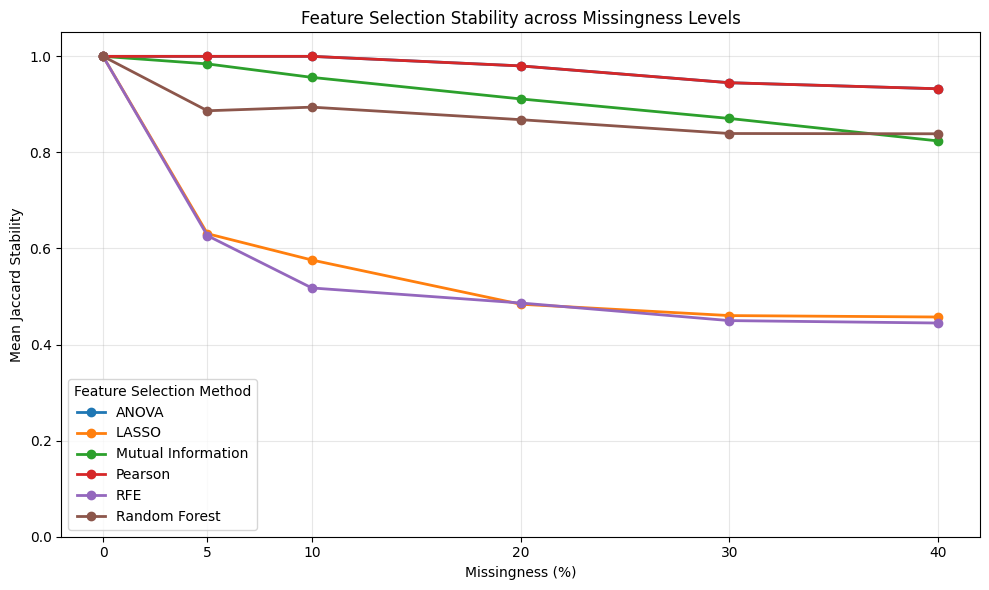

In [211]:
plt.figure(figsize=(10, 6))

for method in fs_stability["Feature_Selection"].unique():

    subset = fs_stability[
        fs_stability["Feature_Selection"] == method
    ].sort_values("Missingness")

    plt.plot(
        subset["Missingness"],
        subset["Average_Jaccard"],
        marker="o",
        linewidth=2,
        label=method
    )

plt.xlabel("Missingness (%)")
plt.ylabel("Mean Jaccard Stability")
plt.title("Feature Selection Stability across Missingness Levels")

plt.xticks([0, 5, 10, 20, 30, 40])
plt.ylim(0, 1.05)

plt.grid(True, alpha=0.3)
plt.legend(title="Feature Selection Method")

plt.tight_layout()

plt.savefig(
    "plots/Figure_6_FS_Method_vs_Stability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [212]:
selected_df = pd.read_csv("results/selected_features.csv")

print("Rows:", len(selected_df))
print(selected_df.head())

Rows: 32400
   Missingness Imputation Feature_Selection  Run               Feature
0          0.0       Mean           Pearson    1  worst concave points
1          0.0       Mean           Pearson    1       worst perimeter
2          0.0       Mean           Pearson    1   mean concave points
3          0.0       Mean           Pearson    1          worst radius
4          0.0       Mean           Pearson    1        mean perimeter


In [213]:
feature_recurrence = (
    selected_df["Feature"]
    .value_counts()
    .reset_index()
)

feature_recurrence.columns = ["Feature", "Selection_Count"]

print(feature_recurrence.head(15))

                 Feature  Selection_Count
0   worst concave points             3204
1           worst radius             3120
2        worst perimeter             2868
3    mean concave points             2819
4             worst area             2760
5            mean radius             2607
6              mean area             2498
7         mean perimeter             2443
8         mean concavity             2306
9        worst concavity             2076
10            area error             1179
11         worst texture              956
12      worst smoothness              885
13          radius error              748
14        worst symmetry              620


In [214]:
feature_recurrence = (
    selected_df["Feature"]
    .value_counts()
    .reset_index()
)

feature_recurrence.columns = ["Feature", "Selection_Count"]

print(feature_recurrence.head(15))

                 Feature  Selection_Count
0   worst concave points             3204
1           worst radius             3120
2        worst perimeter             2868
3    mean concave points             2819
4             worst area             2760
5            mean radius             2607
6              mean area             2498
7         mean perimeter             2443
8         mean concavity             2306
9        worst concavity             2076
10            area error             1179
11         worst texture              956
12      worst smoothness              885
13          radius error              748
14        worst symmetry              620


In [215]:
total_selections = len(selected_df)

feature_recurrence["Selection_Percentage"] = (
    feature_recurrence["Selection_Count"]
    / total_selections
    * 100
)

print(feature_recurrence.head(15))

                 Feature  Selection_Count  Selection_Percentage
0   worst concave points             3204              9.888889
1           worst radius             3120              9.629630
2        worst perimeter             2868              8.851852
3    mean concave points             2819              8.700617
4             worst area             2760              8.518519
5            mean radius             2607              8.046296
6              mean area             2498              7.709877
7         mean perimeter             2443              7.540123
8         mean concavity             2306              7.117284
9        worst concavity             2076              6.407407
10            area error             1179              3.638889
11         worst texture              956              2.950617
12      worst smoothness              885              2.731481
13          radius error              748              2.308642
14        worst symmetry              62

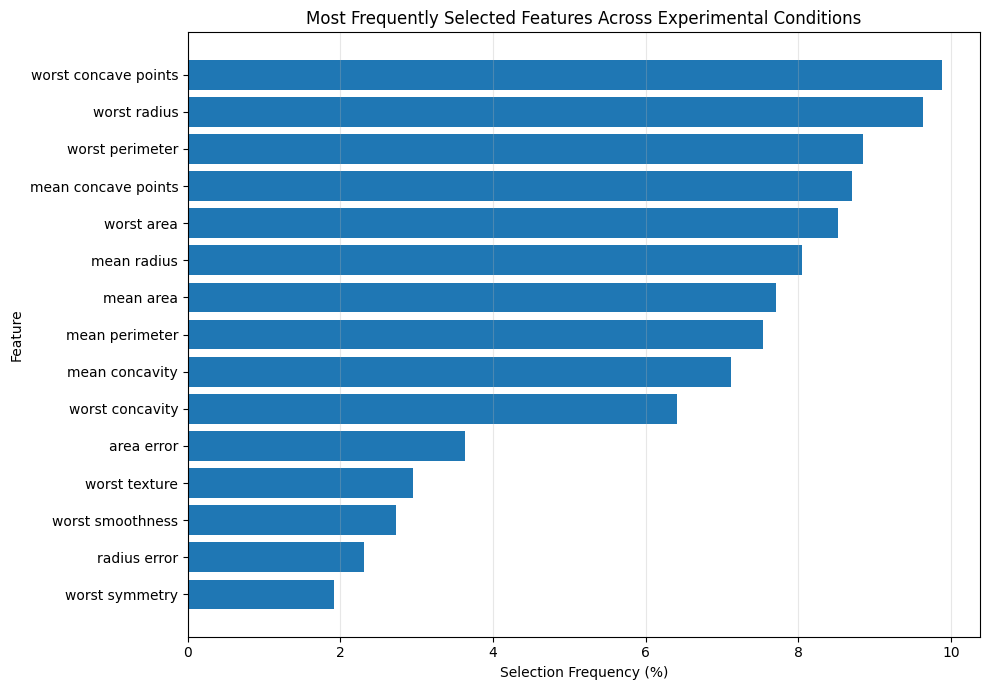

In [216]:
top_features = feature_recurrence.head(15).sort_values(
    "Selection_Percentage"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Selection_Percentage"]
)

plt.xlabel("Selection Frequency (%)")
plt.ylabel("Feature")
plt.title("Most Frequently Selected Features Across Experimental Conditions")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "plots/Figure_7_Feature_Recurrence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

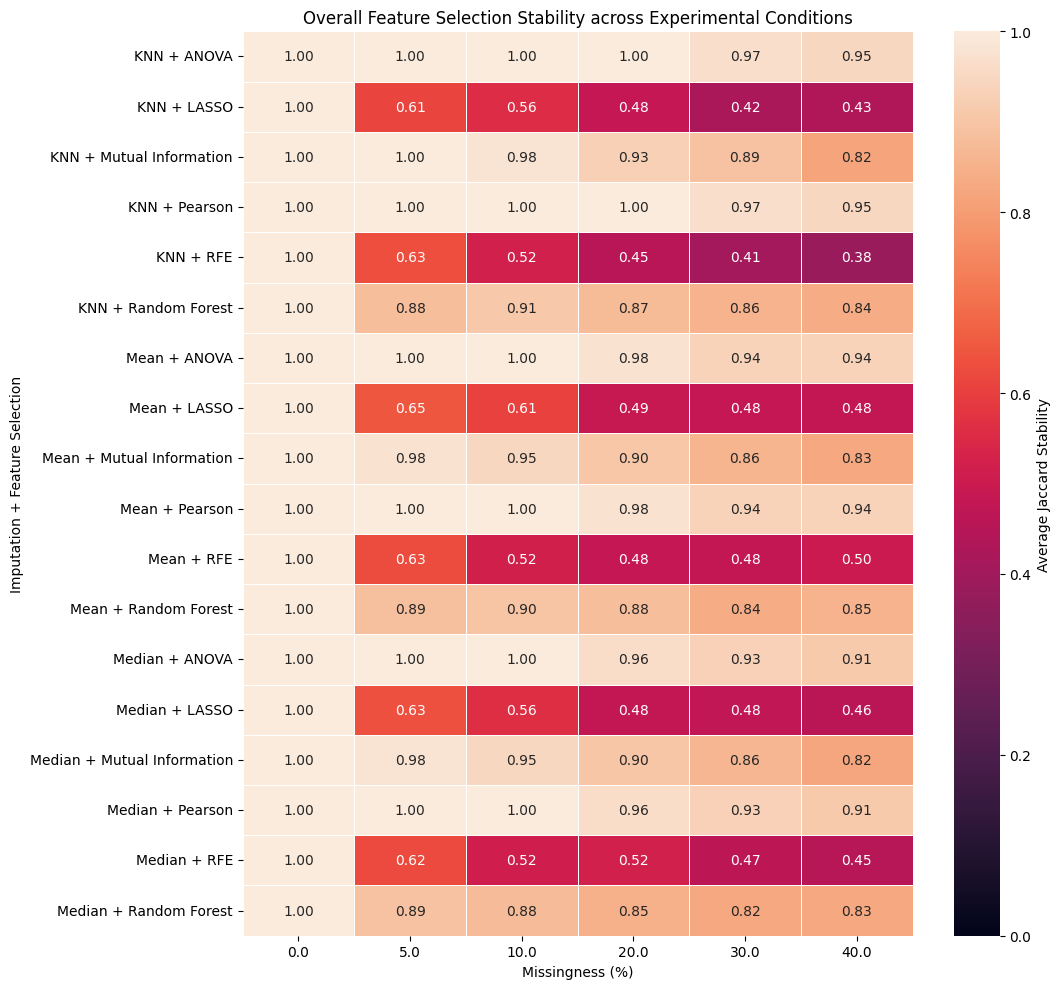

In [217]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a combined label for imputation + feature selection
heatmap_df = stability_df.copy()

heatmap_df["Method"] = (
    heatmap_df["Imputation"]
    + " + "
    + heatmap_df["Feature_Selection"]
)

# Create pivot table
heatmap_data = heatmap_df.pivot(
    index="Method",
    columns="Missingness",
    values="Average_Jaccard"
)

# Sort rows alphabetically
heatmap_data = heatmap_data.sort_index()

# Create heatmap
plt.figure(figsize=(11, 10))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Average Jaccard Stability"}
)

plt.xlabel("Missingness (%)")
plt.ylabel("Imputation + Feature Selection")
plt.title("Overall Feature Selection Stability across Experimental Conditions")

plt.tight_layout()

plt.savefig(
    "plots/Figure_8_Stability_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Master stability table
master_stability = stability_df.copy()

master_stability = master_stability[
    [
        "Missingness",
        "Imputation",
        "Feature_Selection",
        "Top_K",
        "Repetitions",
        "Average_Jaccard",
        "Std_Jaccard",
        "Average_Kuncheva",
        "Std_Kuncheva"
    ]
].sort_values(
    ["Missingness", "Imputation", "Feature_Selection"]
).reset_index(drop=True)

master_stability.to_csv(
    "results/master_stability_results.csv",
    index=False
)

print("Master stability table created!")
print("Rows:", len(master_stability))
display(master_stability.head(20))

In [219]:
# Master prediction performance table
master_performance = performance_summary.copy()

master_performance = master_performance[
    [
        "Missingness",
        "Imputation",
        "Feature_Selection",
        "Mean_Accuracy",
        "Std_Accuracy",
        "Mean_Precision",
        "Std_Precision",
        "Mean_Recall",
        "Std_Recall",
        "Mean_F1",
        "Std_F1",
        "Mean_ROC_AUC",
        "Std_ROC_AUC"
    ]
].sort_values(
    ["Missingness", "Imputation", "Feature_Selection"]
).reset_index(drop=True)

master_performance.to_csv(
    "results/master_performance_results.csv",
    index=False
)

print("Master performance table created!")
print("Rows:", len(master_performance))
display(master_performance.head(20))

Master performance table created!
Rows: 108


,Missingness,Imputation,Feature_Selection,Mean_Accuracy,Std_Accuracy,Mean_Precision,Std_Precision,Mean_Recall,Std_Recall,Mean_F1,Std_F1,Mean_ROC_AUC,Std_ROC_AUC
0,0.0,KNN,ANOVA,0.947368,0.000000,0.971429,0.000000,0.944444,0.00000,0.957746,0.000000,0.992063,0.000000
1,0.0,KNN,LASSO,0.973684,0.000000,0.985915,0.000000,0.972222,0.00000,0.979021,0.000000,0.995370,0.000000
2,0.0,KNN,Mutual Information,0.956140,0.000000,0.971831,0.000000,0.958333,0.00000,0.965035,0.000000,0.991733,0.000000
3,0.0,KNN,Pearson,0.947368,0.000000,0.971429,0.000000,0.944444,0.00000,0.957746,0.000000,0.992063,0.000000
4,0.0,KNN,RFE,0.973684,0.000000,0.985915,0.000000,0.972222,0.00000,0.979021,0.000000,0.996693,0.000000
5,0.0,KNN,Random Forest,0.947368,0.000000,0.971429,0.000000,0.944444,0.00000,0.957746,0.000000,0.992063,0.000000
6,0.0,Mean,ANOVA,0.947368,0.000000,0.971429,0.000000,0.944444,0.00000,0.957746,0.000000,0.992063,0.000000
7,0.0,Mean,LASSO,0.973684,0.000000,0.985915,0.000000,0.972222,0.00000,0.979021,0.000000,0.995370,0.000000
8,0.0,Mean,Mutual Information,0.956140,0.000000,0.971831,0.000000,0.958333,0.00000,0.965035,0.000000,0.991733,0.000000
9,0.0,Mean,Pearson,0.947368,0.000000,0.971429,0.000000,0.944444,0.00000,0.957746,0.000000,0.992063,0.000000


In [220]:
master_results = pd.merge(
    master_stability,
    master_performance,
    on=[
        "Missingness",
        "Imputation",
        "Feature_Selection"
    ],
    how="inner"
)

master_results.to_csv(
    "results/master_results.csv",
    index=False
)

print("MASTER RESULTS CREATED!")
print("Rows:", len(master_results))
print("Columns:", len(master_results.columns))

display(master_results.head(20))

MASTER RESULTS CREATED!
Rows: 108
Columns: 19


,Missingness,Imputation,Feature_Selection,Top_K,Repetitions,Average_Jaccard,Std_Jaccard,Average_Kuncheva,Std_Kuncheva,Mean_Accuracy,Std_Accuracy,Mean_Precision,Std_Precision,Mean_Recall,Std_Recall,Mean_F1,Std_F1,Mean_ROC_AUC,Std_ROC_AUC
0,0.0,KNN,ANOVA,10,30,1.000000,0.00000,1.000000,0.000000,0.947368,0.000000,0.971429,0.000000,0.944444,0.00000,0.957746,0.000000,0.992063,0.000000
1,0.0,KNN,LASSO,10,30,1.000000,0.00000,1.000000,0.000000,0.973684,0.000000,0.985915,0.000000,0.972222,0.00000,0.979021,0.000000,0.995370,0.000000
2,0.0,KNN,Mutual Information,10,30,1.000000,0.00000,1.000000,0.000000,0.956140,0.000000,0.971831,0.000000,0.958333,0.00000,0.965035,0.000000,0.991733,0.000000
3,0.0,KNN,Pearson,10,30,1.000000,0.00000,1.000000,0.000000,0.947368,0.000000,0.971429,0.000000,0.944444,0.00000,0.957746,0.000000,0.992063,0.000000
4,0.0,KNN,RFE,10,30,1.000000,0.00000,1.000000,0.000000,0.973684,0.000000,0.985915,0.000000,0.972222,0.00000,0.979021,0.000000,0.996693,0.000000
5,0.0,KNN,Random Forest,10,30,1.000000,0.00000,1.000000,0.000000,0.947368,0.000000,0.971429,0.000000,0.944444,0.00000,0.957746,0.000000,0.992063,0.000000
6,0.0,Mean,ANOVA,10,30,1.000000,0.00000,1.000000,0.000000,0.947368,0.000000,0.971429,0.000000,0.944444,0.00000,0.957746,0.000000,0.992063,0.000000
7,0.0,Mean,LASSO,10,30,1.000000,0.00000,1.000000,0.000000,0.973684,0.000000,0.985915,0.000000,0.972222,0.00000,0.979021,0.000000,0.995370,0.000000
8,0.0,Mean,Mutual Information,10,30,1.000000,0.00000,1.000000,0.000000,0.956140,0.000000,0.971831,0.000000,0.958333,0.00000,0.965035,0.000000,0.991733,0.000000
9,0.0,Mean,Pearson,10,30,1.000000,0.00000,1.000000,0.000000,0.947368,0.000000,0.971429,0.000000,0.944444,0.00000,0.957746,0.000000,0.992063,0.000000


In [221]:
overall_stability = (
    stability_df
    .groupby("Missingness")
    .agg(
        Mean_Jaccard=("Average_Jaccard", "mean"),
        Mean_Kuncheva=("Average_Kuncheva", "mean")
    )
    .reset_index()
)

overall_performance = (
    performance_summary
    .groupby("Missingness")
    .agg(
        Mean_Accuracy=("Mean_Accuracy", "mean"),
        Mean_F1=("Mean_F1", "mean"),
        Mean_ROC_AUC=("Mean_ROC_AUC", "mean")
    )
    .reset_index()
)

overall_summary = pd.merge(
    overall_stability,
    overall_performance,
    on="Missingness"
)

display(overall_summary)

,Missingness,Mean_Jaccard,Mean_Kuncheva,Mean_Accuracy,Mean_F1,Mean_ROC_AUC
0,0.0,1.000000,1.000000,0.957602,0.966053,0.993331
1,5.0,0.854750,0.863908,0.953590,0.962733,0.992940
2,10.0,0.824072,0.827950,0.948944,0.958791,0.992534
3,20.0,0.785069,0.785881,0.939864,0.951108,0.991772
4,30.0,0.751749,0.752490,0.933041,0.945164,0.991155
5,40.0,0.738326,0.739789,0.924431,0.937661,0.990182


In [222]:
# Detailed stability comparison at each missingness level

method_stability_summary = (
    stability_df
    .groupby(["Missingness", "Feature_Selection"])
    .agg(
        Mean_Jaccard=("Average_Jaccard", "mean"),
        Mean_Kuncheva=("Average_Kuncheva", "mean")
    )
    .reset_index()
)

display(method_stability_summary)

,Missingness,Feature_Selection,Mean_Jaccard,Mean_Kuncheva
0,0.0,ANOVA,1.000000,1.000000
1,0.0,LASSO,1.000000,1.000000
2,0.0,Mutual Information,1.000000,1.000000
3,0.0,Pearson,1.000000,1.000000
4,0.0,RFE,1.000000,1.000000
5,0.0,Random Forest,1.000000,1.000000
6,5.0,ANOVA,1.000000,1.000000
7,5.0,LASSO,0.630798,0.648046
8,5.0,Mutual Information,0.984256,0.987011
9,5.0,Pearson,1.000000,1.000000


In [223]:
# Detailed prediction performance by feature-selection method

method_performance_summary = (
    performance_summary
    .groupby(["Missingness", "Feature_Selection"])
    .agg(
        Mean_Accuracy=("Mean_Accuracy", "mean"),
        Mean_F1=("Mean_F1", "mean"),
        Mean_ROC_AUC=("Mean_ROC_AUC", "mean")
    )
    .reset_index()
)

display(method_performance_summary)

,Missingness,Feature_Selection,Mean_Accuracy,Mean_F1,Mean_ROC_AUC
0,0.0,ANOVA,0.947368,0.957746,0.992063
1,0.0,LASSO,0.973684,0.979021,0.995370
2,0.0,Mutual Information,0.956140,0.965035,0.991733
3,0.0,Pearson,0.947368,0.957746,0.992063
4,0.0,RFE,0.973684,0.979021,0.996693
5,0.0,Random Forest,0.947368,0.957746,0.992063
6,5.0,ANOVA,0.941520,0.952745,0.991527
7,5.0,LASSO,0.965789,0.972615,0.995098
8,5.0,Mutual Information,0.956335,0.965214,0.991670
9,5.0,Pearson,0.941520,0.952745,0.991527


In [224]:
# Detailed stability comparison at each missingness level

method_stability_summary = (
    stability_df
    .groupby(["Missingness", "Feature_Selection"])
    .agg(
        Mean_Jaccard=("Average_Jaccard", "mean"),
        Mean_Kuncheva=("Average_Kuncheva", "mean")
    )
    .reset_index()
)

display(method_stability_summary)

,Missingness,Feature_Selection,Mean_Jaccard,Mean_Kuncheva
0,0.0,ANOVA,1.000000,1.000000
1,0.0,LASSO,1.000000,1.000000
2,0.0,Mutual Information,1.000000,1.000000
3,0.0,Pearson,1.000000,1.000000
4,0.0,RFE,1.000000,1.000000
5,0.0,Random Forest,1.000000,1.000000
6,5.0,ANOVA,1.000000,1.000000
7,5.0,LASSO,0.630798,0.648046
8,5.0,Mutual Information,0.984256,0.987011
9,5.0,Pearson,1.000000,1.000000


In [225]:
# Detailed prediction performance by feature-selection method

method_performance_summary = (
    performance_summary
    .groupby(["Missingness", "Feature_Selection"])
    .agg(
        Mean_Accuracy=("Mean_Accuracy", "mean"),
        Mean_F1=("Mean_F1", "mean"),
        Mean_ROC_AUC=("Mean_ROC_AUC", "mean")
    )
    .reset_index()
)

display(method_performance_summary)

,Missingness,Feature_Selection,Mean_Accuracy,Mean_F1,Mean_ROC_AUC
0,0.0,ANOVA,0.947368,0.957746,0.992063
1,0.0,LASSO,0.973684,0.979021,0.995370
2,0.0,Mutual Information,0.956140,0.965035,0.991733
3,0.0,Pearson,0.947368,0.957746,0.992063
4,0.0,RFE,0.973684,0.979021,0.996693
5,0.0,Random Forest,0.947368,0.957746,0.992063
6,5.0,ANOVA,0.941520,0.952745,0.991527
7,5.0,LASSO,0.965789,0.972615,0.995098
8,5.0,Mutual Information,0.956335,0.965214,0.991670
9,5.0,Pearson,0.941520,0.952745,0.991527


In [226]:
imputation_stability_summary = (
    stability_df
    .groupby(["Missingness", "Imputation"])
    .agg(
        Mean_Jaccard=("Average_Jaccard", "mean"),
        Mean_Kuncheva=("Average_Kuncheva", "mean")
    )
    .reset_index()
)

display(imputation_stability_summary)

,Missingness,Imputation,Mean_Jaccard,Mean_Kuncheva
0,0.0,KNN,1.000000,1.000000
1,0.0,Mean,1.000000,1.000000
2,0.0,Median,1.000000,1.000000
3,5.0,KNN,0.854116,0.862414
4,5.0,Mean,0.855993,0.865862
5,5.0,Median,0.854142,0.863448
6,10.0,KNN,0.827416,0.829425
7,10.0,Mean,0.827817,0.833391
8,10.0,Median,0.816984,0.821034
9,20.0,KNN,0.789785,0.787184


In [227]:
# Feature recurrence by missingness level

feature_recurrence_missingness = (
    selected_df
    .groupby(["Missingness", "Feature"])["Run"]
    .count()
    .reset_index(name="Selection_Count")
)

# Total individual feature selections at each missingness level:
# 3 imputations × 6 methods × 30 runs × 10 selected features
total_selections_per_missingness = 3 * 6 * 30 * 10

feature_recurrence_missingness["Selection_Percentage"] = (
    feature_recurrence_missingness["Selection_Count"]
    / total_selections_per_missingness
    * 100
)

display(
    feature_recurrence_missingness
    .sort_values(
        ["Missingness", "Selection_Percentage"],
        ascending=[True, False]
    ).head(30)
)

,Missingness,Feature,Selection_Count,Selection_Percentage
9,0.0,worst concave points,540,10.000000
12,0.0,worst radius,540,10.000000
1,0.0,mean area,450,8.333333
2,0.0,mean concave points,450,8.333333
5,0.0,mean radius,450,8.333333
8,0.0,worst area,450,8.333333
10,0.0,worst concavity,450,8.333333
11,0.0,worst perimeter,450,8.333333
3,0.0,mean concavity,360,6.666667
4,0.0,mean perimeter,360,6.666667


In [228]:
# Find the 10 most frequently selected features overall
top_10_features = (
    selected_df["Feature"]
    .value_counts()
    .head(10)
    .index
)

# Calculate their recurrence at each missingness level
recurrence_top10 = (
    selected_df[
        selected_df["Feature"].isin(top_10_features)
    ]
    .groupby(["Missingness", "Feature"])
    .size()
    .reset_index(name="Selection_Count")
)

# Convert selection count to percentage
recurrence_top10["Selection_Percentage"] = (
    recurrence_top10["Selection_Count"]
    / (3 * 6 * 30 * 10)
    * 100
)

display(recurrence_top10)

,Missingness,Feature,Selection_Count,Selection_Percentage
0,0.0,mean area,450,8.333333
1,0.0,mean concave points,450,8.333333
2,0.0,mean concavity,360,6.666667
3,0.0,mean perimeter,360,6.666667
4,0.0,mean radius,450,8.333333
5,0.0,worst area,450,8.333333
6,0.0,worst concave points,540,10.000000
7,0.0,worst concavity,450,8.333333
8,0.0,worst perimeter,450,8.333333
9,0.0,worst radius,540,10.000000


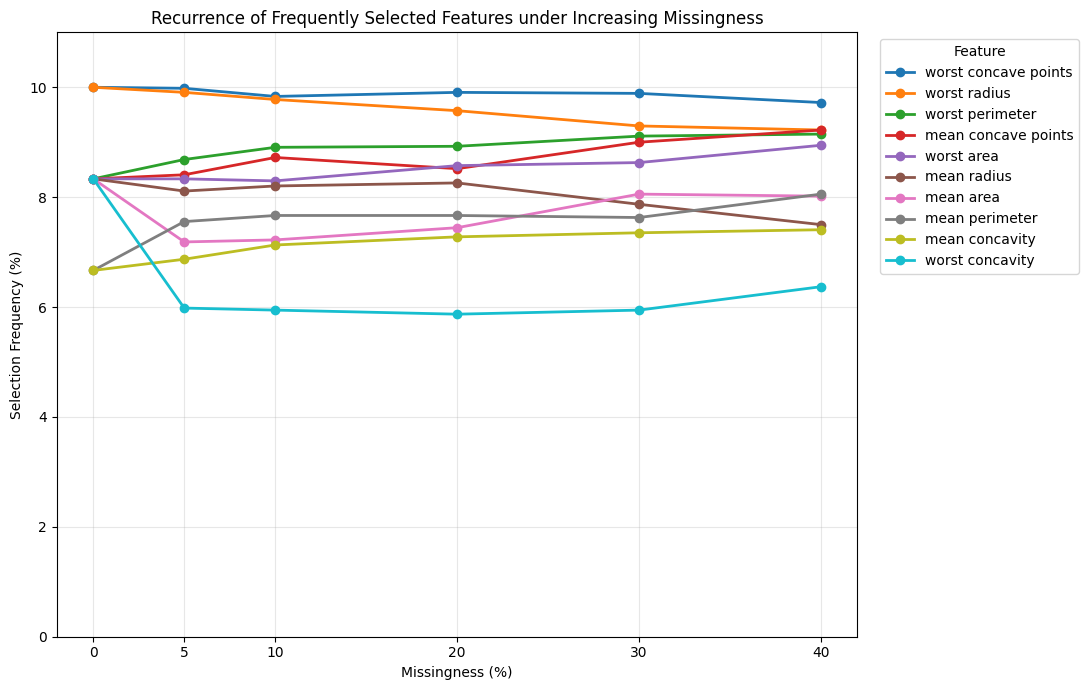

In [229]:
plt.figure(figsize=(11, 7))

for feature in top_10_features:

    subset = recurrence_top10[
        recurrence_top10["Feature"] == feature
    ].sort_values("Missingness")

    plt.plot(
        subset["Missingness"],
        subset["Selection_Percentage"],
        marker="o",
        linewidth=2,
        label=feature
    )

plt.xlabel("Missingness (%)")
plt.ylabel("Selection Frequency (%)")
plt.title(
    "Recurrence of Frequently Selected Features "
    "under Increasing Missingness"
)

plt.xticks([0, 5, 10, 20, 30, 40])
plt.ylim(0, 11)

plt.grid(True, alpha=0.3)

plt.legend(
    title="Feature",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    "plots/Figure_7_Feature_Recurrence_FinalDraft.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [230]:
# Feature recurrence rate at each missingness level

feature_recurrence = (
    selected_df.groupby(["Missingness", "Feature"])
    .size()
    .reset_index(name="Selection_Count")
)

# 540 runs at each missingness level
total_runs_per_missingness = 3 * 6 * 30

feature_recurrence["Recurrence_Rate"] = (
    feature_recurrence["Selection_Count"]
    / total_runs_per_missingness * 100
)

# Top 10 features overall
top_features = (
    feature_recurrence.groupby("Feature")["Selection_Count"]
    .sum()
    .nlargest(10)
    .index
)

recurrence_top10 = feature_recurrence[
    feature_recurrence["Feature"].isin(top_features)
]

display(
    recurrence_top10.sort_values(
        ["Missingness", "Recurrence_Rate"],
        ascending=[True, False]
    )
)

,Missingness,Feature,Selection_Count,Recurrence_Rate
9,0.0,worst concave points,540,100.000000
12,0.0,worst radius,540,100.000000
1,0.0,mean area,450,83.333333
2,0.0,mean concave points,450,83.333333
5,0.0,mean radius,450,83.333333
8,0.0,worst area,450,83.333333
10,0.0,worst concavity,450,83.333333
11,0.0,worst perimeter,450,83.333333
3,0.0,mean concavity,360,66.666667
4,0.0,mean perimeter,360,66.666667


In [231]:
!mkdir -p final_results
!cp -r results final_results/
!cp -r plots final_results/

In [ ]:
!zip -r project_results_backup.zip results plots

In [233]:
from google.colab import files
files.download("project_results_backup.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [234]:
import os

print("results folder exists:", os.path.exists("results"))
print("plots folder exists:", os.path.exists("plots"))
print("selected_features.csv exists:",
      os.path.exists("results/selected_features.csv"))
print("stability_results.csv exists:",
      os.path.exists("results/stability_results.csv"))
print("performance_results.csv exists:",
      os.path.exists("results/performance_results.csv"))

print("\nFiles in results:")
if os.path.exists("results"):
    print(os.listdir("results"))

results folder exists: True
plots folder exists: True
selected_features.csv exists: True
stability_results.csv exists: True
performance_results.csv exists: True

Files in results:
['master_performance_results.csv', 'stability_results.csv', 'performance_results.csv', 'performance_summary.csv', 'pilot_result.csv', 'selected_features.csv', 'master_stability_results.csv', 'master_results.csv']


In [235]:
import pandas as pd

selected_df = pd.read_csv("results/selected_features.csv")
stability_df = pd.read_csv("results/stability_results.csv")
performance_df = pd.read_csv("results/performance_results.csv")
performance_summary_df = pd.read_csv("results/performance_summary.csv")

print("Selected features:", selected_df.shape)
print("Stability:", stability_df.shape)
print("Performance:", performance_df.shape)
print("Performance summary:", performance_summary_df.shape)

Selected features: (32400, 5)
Stability: (108, 10)
Performance: (3240, 9)
Performance summary: (108, 13)


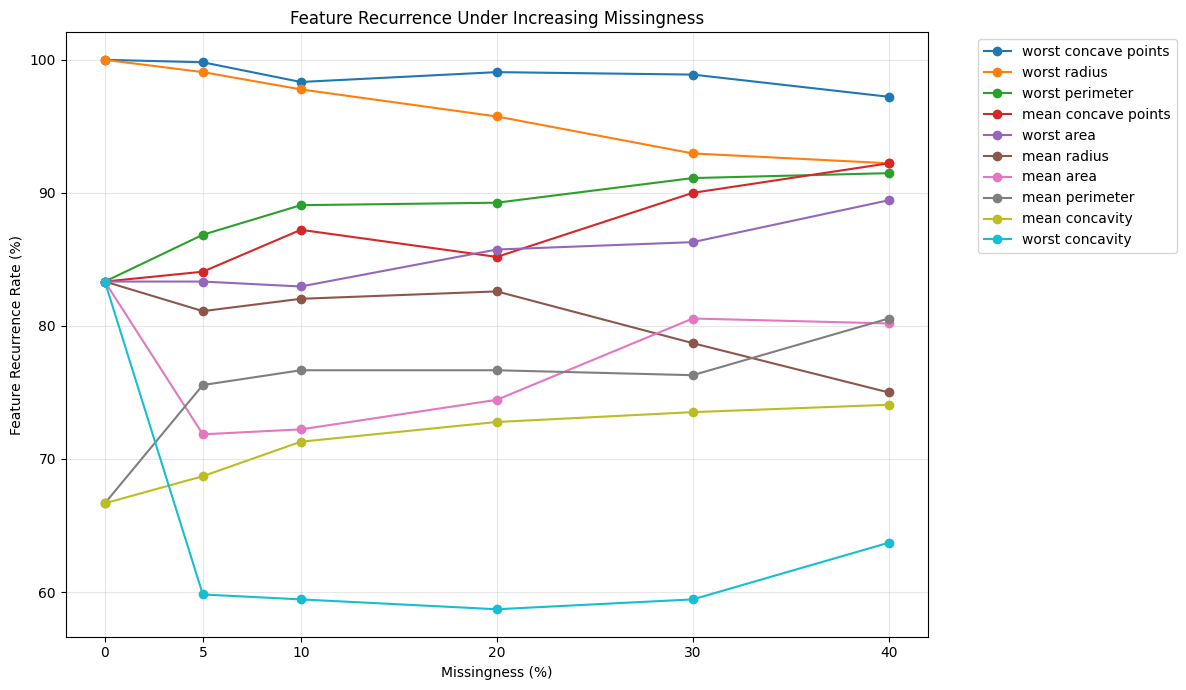

In [236]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

for feature in top_features:
    temp = recurrence_top10[
        recurrence_top10["Feature"] == feature
    ].sort_values("Missingness")

    plt.plot(
        temp["Missingness"],
        temp["Recurrence_Rate"],
        marker="o",
        label=feature
    )

plt.xlabel("Missingness (%)")
plt.ylabel("Feature Recurrence Rate (%)")
plt.title("Feature Recurrence Under Increasing Missingness")
plt.xticks([0, 5, 10, 20, 30, 40])
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "plots/Figure_7_Feature_Recurrence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [237]:
# Overall results by missingness level

overall_results = (
    stability_df.groupby("Missingness")
    .agg(
        Average_Jaccard=("Average_Jaccard", "mean"),
        Average_Kuncheva=("Average_Kuncheva", "mean")
    )
    .reset_index()
)

performance_overall = (
    performance_summary_df.groupby("Missingness")
    .agg(
        Average_Accuracy=("Mean_Accuracy", "mean"),
        Average_F1=("Mean_F1", "mean"),
        Average_ROC_AUC=("Mean_ROC_AUC", "mean")
    )
    .reset_index()
)

final_overall_table = overall_results.merge(
    performance_overall,
    on="Missingness"
)

display(final_overall_table.round(4))

,Missingness,Average_Jaccard,Average_Kuncheva,Average_Accuracy,Average_F1,Average_ROC_AUC
0,0.0,1.0000,1.0000,0.9576,0.9661,0.9933
1,5.0,0.8548,0.8639,0.9536,0.9627,0.9929
2,10.0,0.8241,0.8280,0.9489,0.9588,0.9925
3,20.0,0.7851,0.7859,0.9399,0.9511,0.9918
4,30.0,0.7517,0.7525,0.9330,0.9452,0.9912
5,40.0,0.7383,0.7398,0.9244,0.9377,0.9902


In [239]:
method_stability_table = (
    stability_df
    .groupby(["Missingness", "Feature_Selection"])
    .agg(
        Average_Jaccard=("Average_Jaccard", "mean"),
        Average_Kuncheva=("Average_Kuncheva", "mean")
    )
    .reset_index()
)

display(method_stability_table)

,Missingness,Feature_Selection,Average_Jaccard,Average_Kuncheva
0,0.0,ANOVA,1.000000,1.000000
1,0.0,LASSO,1.000000,1.000000
2,0.0,Mutual Information,1.000000,1.000000
3,0.0,Pearson,1.000000,1.000000
4,0.0,RFE,1.000000,1.000000
5,0.0,Random Forest,1.000000,1.000000
6,5.0,ANOVA,1.000000,1.000000
7,5.0,LASSO,0.630798,0.648046
8,5.0,Mutual Information,0.984256,0.987011
9,5.0,Pearson,1.000000,1.000000


In [241]:
print(stability_df.columns.tolist())

['Missingness', 'Imputation', 'Feature_Selection', 'Top_K', 'Repetitions', 'Pairwise_Comparisons', 'Average_Jaccard', 'Std_Jaccard', 'Average_Kuncheva', 'Std_Kuncheva']


In [240]:
# Method-wise stability across missingness levels

method_stability_table = (
    stability_df
    .groupby(["Missingness", "Feature_Selection"])
    .agg(
        Average_Jaccard=("Average_Jaccard", "mean"),
        Average_Kuncheva=("Average_Kuncheva", "mean")
    )
    .reset_index()
)

display(method_stability_table.round(4))

,Missingness,Feature_Selection,Average_Jaccard,Average_Kuncheva
0,0.0,ANOVA,1.0000,1.0000
1,0.0,LASSO,1.0000,1.0000
2,0.0,Mutual Information,1.0000,1.0000
3,0.0,Pearson,1.0000,1.0000
4,0.0,RFE,1.0000,1.0000
5,0.0,Random Forest,1.0000,1.0000
6,5.0,ANOVA,1.0000,1.0000
7,5.0,LASSO,0.6308,0.6480
8,5.0,Mutual Information,0.9843,0.9870
9,5.0,Pearson,1.0000,1.0000


In [242]:
# Method-wise predictive performance across missingness levels

print(performance_summary_df.columns.tolist())

['Missingness', 'Imputation', 'Feature_Selection', 'Mean_Accuracy', 'Std_Accuracy', 'Mean_Precision', 'Std_Precision', 'Mean_Recall', 'Std_Recall', 'Mean_F1', 'Std_F1', 'Mean_ROC_AUC', 'Std_ROC_AUC']


In [243]:
# Method-wise predictive performance across missingness levels

method_performance_table = (
    performance_summary_df
    .groupby(["Missingness", "Feature_Selection"])
    .agg(
        Average_Accuracy=("Mean_Accuracy", "mean"),
        Average_Precision=("Mean_Precision", "mean"),
        Average_Recall=("Mean_Recall", "mean"),
        Average_F1=("Mean_F1", "mean"),
        Average_ROC_AUC=("Mean_ROC_AUC", "mean")
    )
    .reset_index()
)

display(method_performance_table.round(4))

,Missingness,Feature_Selection,Average_Accuracy,Average_Precision,Average_Recall,Average_F1,Average_ROC_AUC
0,0.0,ANOVA,0.9474,0.9714,0.9444,0.9577,0.9921
1,0.0,LASSO,0.9737,0.9859,0.9722,0.9790,0.9954
2,0.0,Mutual Information,0.9561,0.9718,0.9583,0.9650,0.9917
3,0.0,Pearson,0.9474,0.9714,0.9444,0.9577,0.9921
4,0.0,RFE,0.9737,0.9859,0.9722,0.9790,0.9967
5,0.0,Random Forest,0.9474,0.9714,0.9444,0.9577,0.9921
6,5.0,ANOVA,0.9415,0.9711,0.9352,0.9527,0.9915
7,5.0,LASSO,0.9658,0.9812,0.9644,0.9726,0.9951
8,5.0,Mutual Information,0.9563,0.9703,0.9603,0.9652,0.9917
9,5.0,Pearson,0.9415,0.9711,0.9352,0.9527,0.9915


In [244]:
# Imputation-wise stability across missingness levels

imputation_stability_table = (
    stability_df
    .groupby(["Missingness", "Imputation"])
    .agg(
        Average_Jaccard=("Average_Jaccard", "mean"),
        Average_Kuncheva=("Average_Kuncheva", "mean")
    )
    .reset_index()
)

display(imputation_stability_table.round(4))

,Missingness,Imputation,Average_Jaccard,Average_Kuncheva
0,0.0,KNN,1.0000,1.0000
1,0.0,Mean,1.0000,1.0000
2,0.0,Median,1.0000,1.0000
3,5.0,KNN,0.8541,0.8624
4,5.0,Mean,0.8560,0.8659
5,5.0,Median,0.8541,0.8634
6,10.0,KNN,0.8274,0.8294
7,10.0,Mean,0.8278,0.8334
8,10.0,Median,0.8170,0.8210
9,20.0,KNN,0.7898,0.7872


In [245]:
# Imputation-wise predictive performance

imputation_performance_table = (
    performance_summary_df
    .groupby(["Missingness", "Imputation"])
    .agg(
        Average_Accuracy=("Mean_Accuracy", "mean"),
        Average_F1=("Mean_F1", "mean"),
        Average_ROC_AUC=("Mean_ROC_AUC", "mean")
    )
    .reset_index()
)

display(imputation_performance_table.round(4))

,Missingness,Imputation,Average_Accuracy,Average_F1,Average_ROC_AUC
0,0.0,KNN,0.9576,0.9661,0.9933
1,0.0,Mean,0.9576,0.9661,0.9933
2,0.0,Median,0.9576,0.9661,0.9933
3,5.0,KNN,0.9592,0.9675,0.9932
4,5.0,Mean,0.9545,0.9635,0.9928
5,5.0,Median,0.9471,0.9572,0.9928
6,10.0,KNN,0.9601,0.9682,0.9931
7,10.0,Mean,0.9498,0.9596,0.9924
8,10.0,Median,0.9369,0.9485,0.9922
9,20.0,KNN,0.9493,0.9592,0.9926


In [246]:
# Combine stability and performance summaries

stability_summary = (
    stability_df
    .groupby(["Missingness", "Imputation", "Feature_Selection"])
    .agg(
        Average_Jaccard=("Average_Jaccard", "mean"),
        Average_Kuncheva=("Average_Kuncheva", "mean")
    )
    .reset_index()
)

performance_summary = (
    performance_summary_df
    .groupby(["Missingness", "Imputation", "Feature_Selection"])
    .agg(
        Average_Accuracy=("Mean_Accuracy", "mean"),
        Average_F1=("Mean_F1", "mean"),
        Average_ROC_AUC=("Mean_ROC_AUC", "mean")
    )
    .reset_index()
)

combined_results = stability_summary.merge(
    performance_summary,
    on=["Missingness", "Imputation", "Feature_Selection"]
)

display(combined_results.round(4))

,Missingness,Imputation,Feature_Selection,Average_Jaccard,Average_Kuncheva,Average_Accuracy,Average_F1,Average_ROC_AUC
0,0.0,KNN,ANOVA,1.0000,1.0000,0.9474,0.9577,0.9921
1,0.0,KNN,LASSO,1.0000,1.0000,0.9737,0.9790,0.9954
2,0.0,KNN,Mutual Information,1.0000,1.0000,0.9561,0.9650,0.9917
3,0.0,KNN,Pearson,1.0000,1.0000,0.9474,0.9577,0.9921
4,0.0,KNN,RFE,1.0000,1.0000,0.9737,0.9790,0.9967
...,...,...,...,...,...,...,...,...
103,40.0,Median,LASSO,0.4599,0.4331,0.9111,0.9250,0.9933
104,40.0,Median,Mutual Information,0.8220,0.8486,0.9091,0.9235,0.9878
105,40.0,Median,Pearson,0.9133,0.9279,0.9067,0.9214,0.9872
106,40.0,Median,RFE,0.4512,0.4193,0.9216,0.9344,0.9939


In [247]:
# Correlation between feature-selection stability and predictive accuracy

pearson_corr = combined_results["Average_Jaccard"].corr(
    combined_results["Average_Accuracy"],
    method="pearson"
)

spearman_corr = combined_results["Average_Jaccard"].corr(
    combined_results["Average_Accuracy"],
    method="spearman"
)

print("Pearson correlation:", round(pearson_corr, 4))
print("Spearman correlation:", round(spearman_corr, 4))

Pearson correlation: -0.2001
Spearman correlation: -0.0246


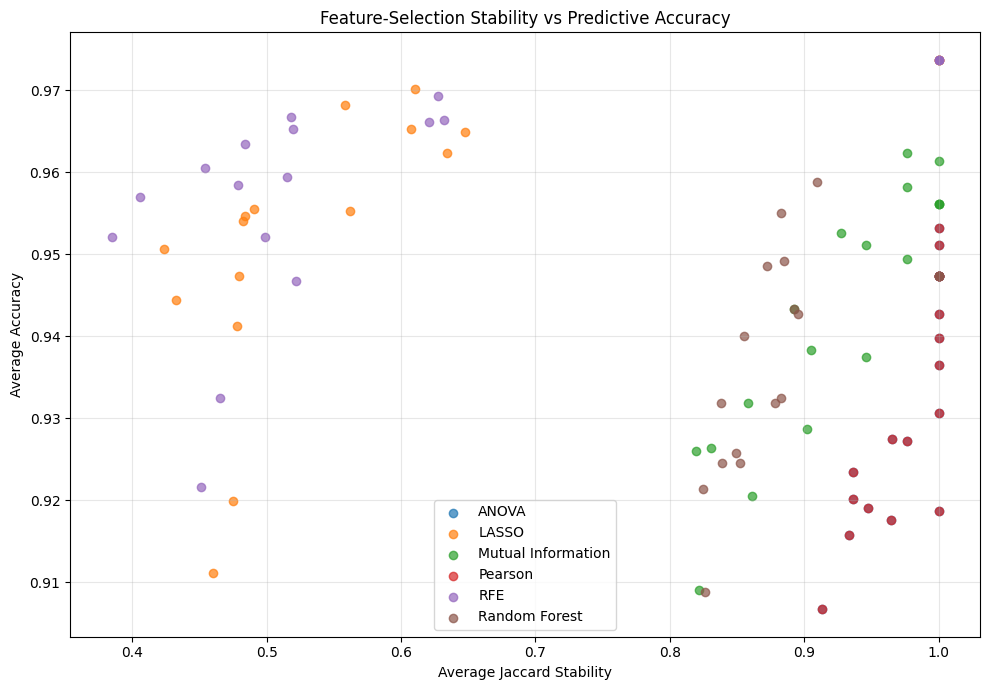

In [248]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for method in combined_results["Feature_Selection"].unique():
    temp = combined_results[
        combined_results["Feature_Selection"] == method
    ]

    plt.scatter(
        temp["Average_Jaccard"],
        temp["Average_Accuracy"],
        label=method,
        alpha=0.7
    )

plt.xlabel("Average Jaccard Stability")
plt.ylabel("Average Accuracy")
plt.title("Feature-Selection Stability vs Predictive Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "plots/Figure_4_Stability_vs_Accuracy_Final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [249]:
import os
import shutil

# Main project folder
project_folder = "Feature_Selection_Stability_Project"

# Remove old package if it exists
if os.path.exists(project_folder):
    shutil.rmtree(project_folder)

# Create folder structure
os.makedirs(f"{project_folder}/01_Colab_Notebook")
os.makedirs(f"{project_folder}/02_Raw_Results")
os.makedirs(f"{project_folder}/03_Final_Results")
os.makedirs(f"{project_folder}/04_Figures")
os.makedirs(f"{project_folder}/05_Project_Notes")

# Copy results
if os.path.exists("results"):
    for file in os.listdir("results"):
        shutil.copy(
            f"results/{file}",
            f"{project_folder}/02_Raw_Results/{file}"
        )

# Copy plots
if os.path.exists("plots"):
    for file in os.listdir("plots"):
        shutil.copy(
            f"plots/{file}",
            f"{project_folder}/04_Figures/{file}"
        )

# Create README
readme_text = """PROJECT: Feature Selection Stability Under Missing Data

Dataset:
Breast Cancer Wisconsin (Diagnostic)

Dataset size:
569 samples, 30 features

Train/test split:
80/20 stratified split
Random state = 42

Missingness:
0%, 5%, 10%, 20%, 30%, 40%

Missingness mechanism:
MCAR

Imputation:
Mean, Median, KNN

Feature-selection methods:
Pearson Correlation
ANOVA F-test
Mutual Information
Random Forest Importance
LASSO
RFE

Number of selected features:
Top 10

Repetitions:
30 per experimental condition

Total experimental runs:
3,240

Stability metrics:
Jaccard Similarity
Kuncheva Index

Prediction model:
Logistic Regression

Performance metrics:
Accuracy
Precision
Recall
F1-score
ROC-AUC

Correlation analysis:
Pearson correlation = -0.2001
Spearman correlation = -0.0246

The CSV files contain the experimental results.
The figures contain the visualizations generated from the results.
"""

with open(f"{project_folder}/05_Project_Notes/README.txt", "w") as f:
    f.write(readme_text)

print("Project folder created successfully!")

Project folder created successfully!


In [250]:
import shutil

zip_file = shutil.make_archive(
    "Feature_Selection_Stability_Project",
    "zip",
    ".",
    "Feature_Selection_Stability_Project"
)

print("ZIP created:", zip_file)

ZIP created: /content/Feature_Selection_Stability_Project.zip


In [251]:
from google.colab import files

files.download("Feature_Selection_Stability_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [252]:
import os

# Create final results folder
os.makedirs("03_Final_Results", exist_ok=True)

# Save final summary tables
final_overall_table.to_csv(
    "03_Final_Results/overall_results_table.csv",
    index=False
)

method_stability_table.to_csv(
    "03_Final_Results/method_stability_table.csv",
    index=False
)

method_performance_table.to_csv(
    "03_Final_Results/method_performance_table.csv",
    index=False
)

imputation_stability_table.to_csv(
    "03_Final_Results/imputation_stability_table.csv",
    index=False
)

imputation_performance_table.to_csv(
    "03_Final_Results/imputation_performance_table.csv",
    index=False
)

combined_results.to_csv(
    "03_Final_Results/combined_results.csv",
    index=False
)

print("Final results files created:")
print(os.listdir("03_Final_Results"))

Final results files created:
['combined_results.csv', 'method_performance_table.csv', 'method_stability_table.csv', 'imputation_performance_table.csv', 'overall_results_table.csv', 'imputation_stability_table.csv']


In [253]:
import os
import time
import numpy as np
import pandas as pd

from itertools import combinations
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

os.makedirs("results_mar", exist_ok=True)

# MAR: missingness depends on the observed "mean radius" feature.
# The driver feature itself is kept observed.

def introduce_mar(X, rate, seed=42):
    X_mar = X.copy()

    if rate == 0:
        return X_mar

    rng = np.random.default_rng(seed)

    driver = X_mar["mean radius"].to_numpy()
    z = (driver - driver.mean()) / (driver.std() + 1e-12)

    columns = list(X_mar.columns)
    driver_idx = columns.index("mean radius")

    eligible = [
        (i, j)
        for i in range(len(X_mar))
        for j in range(len(columns))
        if j != driver_idx
    ]

    target = int(X_mar.size * rate)
    target = min(target, len(eligible))

    # Higher observed mean radius increases missingness probability.
    weights = np.array([
        np.exp(np.clip(1.2 * z[i], -20, 20))
        for i, j in eligible
    ])
    weights = weights / weights.sum()

    chosen = rng.choice(
        len(eligible),
        size=target,
        replace=False,
        p=weights
    )

    values = X_mar.to_numpy().copy()

    for idx in chosen:
        i, j = eligible[idx]
        values[i, j] = np.nan

    return pd.DataFrame(
        values,
        columns=columns,
        index=X_mar.index
    )


mar_stability = []
mar_performance = []
mar_selected = []

levels = [0, 5, 10, 20, 30, 40]
imputations = ["Mean", "Median", "KNN"]
methods = [
    "Pearson",
    "ANOVA",
    "Mutual Information",
    "Random Forest",
    "LASSO",
    "RFE"
]

repetitions = 30
k = 10
N = X_train.shape[1]

for level in levels:
    for imp in imputations:
        for method in methods:

            feature_sets = []

            for run in range(30):
                start = time.perf_counter()

                X_missing = introduce_mar(
                    X_train,
                    level / 100,
                    seed=3000 + run
                )

                X_imp, fitted_imputer = impute_data(
                    X_missing, imp
                )

                selected = select_features(
                    X_imp, y_train, method, k
                )

                feature_sets.append(set(selected))

                for feature in selected:
                    mar_selected.append({
                        "Missingness": level,
                        "Imputation": imp,
                        "Feature_Selection": method,
                        "Run": run + 1,
                        "Feature": feature
                    })

                X_test_imp = pd.DataFrame(
                    fitted_imputer.transform(X_test),
                    columns=X_test.columns,
                    index=X_test.index
                )

                model = Pipeline([
                    ("scaler", StandardScaler()),
                    ("classifier", LogisticRegression(max_iter=5000))
                ])

                model.fit(X_imp[selected], y_train)

                pred = model.predict(X_test_imp[selected])
                prob = model.predict_proba(X_test_imp[selected])[:, 1]

                mar_performance.append({
                    "Missingness": level,
                    "Imputation": imp,
                    "Feature_Selection": method,
                    "Run": run + 1,
                    "Accuracy": accuracy_score(y_test, pred),
                    "Precision": precision_score(
                        y_test, pred, zero_division=0
                    ),
                    "Recall": recall_score(
                        y_test, pred, zero_division=0
                    ),
                    "F1": f1_score(
                        y_test, pred, zero_division=0
                    ),
                    "ROC_AUC": roc_auc_score(y_test, prob),
                    "Runtime_Seconds": time.perf_counter() - start
                })

            jac = []
            kun = []

            for a, b in combinations(feature_sets, 2):
                intersection = len(a & b)
                union = len(a | b)

                jac.append(intersection / union if union else 0)

                kun.append(
                    (intersection - k**2 / N) /
                    (k - k**2 / N)
                )

            mar_stability.append({
                "Missingness": level,
                "Imputation": imp,
                "Feature_Selection": method,
                "Average_Jaccard": np.mean(jac),
                "Average_Kuncheva": np.mean(kun)
            })

            print(f"Completed: MAR {level}% | {imp} | {method}")


mar_stability_df = pd.DataFrame(mar_stability)
mar_performance_df = pd.DataFrame(mar_performance)
mar_selected_df = pd.DataFrame(mar_selected)

mar_summary_df = (
    mar_performance_df
    .groupby(["Missingness", "Imputation", "Feature_Selection"])
    .agg(
        Average_Accuracy=("Accuracy", "mean"),
        Average_Precision=("Precision", "mean"),
        Average_Recall=("Recall", "mean"),
        Average_F1=("F1", "mean"),
        Average_ROC_AUC=("ROC_AUC", "mean"),
        Average_Runtime_Seconds=("Runtime_Seconds", "mean")
    )
    .reset_index()
)

mar_stability_df.to_csv(
    "results_mar/mar_stability_results.csv", index=False
)

mar_performance_df.to_csv(
    "results_mar/mar_performance_results.csv", index=False
)

mar_selected_df.to_csv(
    "results_mar/mar_selected_features.csv", index=False
)

mar_summary_df.to_csv(
    "results_mar/mar_performance_summary.csv", index=False
)

print("\nMAR EXPERIMENT COMPLETED")
print("Stability rows:", len(mar_stability_df))
print("Performance rows:", len(mar_performance_df))
print("Selected-feature rows:", len(mar_selected_df))

display(mar_stability_df.head())

Completed: MAR 0% | Mean | Pearson
Completed: MAR 0% | Mean | ANOVA
Completed: MAR 0% | Mean | Mutual Information
Completed: MAR 0% | Mean | Random Forest
Completed: MAR 0% | Mean | LASSO
Completed: MAR 0% | Mean | RFE
Completed: MAR 0% | Median | Pearson
Completed: MAR 0% | Median | ANOVA
Completed: MAR 0% | Median | Mutual Information
Completed: MAR 0% | Median | Random Forest
Completed: MAR 0% | Median | LASSO
Completed: MAR 0% | Median | RFE
Completed: MAR 0% | KNN | Pearson
Completed: MAR 0% | KNN | ANOVA
Completed: MAR 0% | KNN | Mutual Information
Completed: MAR 0% | KNN | Random Forest
Completed: MAR 0% | KNN | LASSO
Completed: MAR 0% | KNN | RFE
Completed: MAR 5% | Mean | Pearson
Completed: MAR 5% | Mean | ANOVA
Completed: MAR 5% | Mean | Mutual Information
Completed: MAR 5% | Mean | Random Forest
Completed: MAR 5% | Mean | LASSO
Completed: MAR 5% | Mean | RFE
Completed: MAR 5% | Median | Pearson
Completed: MAR 5% | Median | ANOVA
Completed: MAR 5% | Median | Mutual Informatio

,Missingness,Imputation,Feature_Selection,Average_Jaccard,Average_Kuncheva
0,0,Mean,Pearson,1.0,1.0
1,0,Mean,ANOVA,1.0,1.0
2,0,Mean,Mutual Information,1.0,1.0
3,0,Mean,Random Forest,1.0,1.0
4,0,Mean,LASSO,1.0,1.0


In [254]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("results_comparison", exist_ok=True)
os.makedirs("plots_comparison", exist_ok=True)

# Load existing MCAR results
mcar_stability = pd.read_csv("results/stability_results.csv")
mcar_performance = pd.read_csv("results/performance_results.csv")

# Use the newly generated MAR results
mar_stability_data = pd.read_csv(
    "results_mar/mar_stability_results.csv"
)
mar_performance_data = pd.read_csv(
    "results_mar/mar_performance_results.csv"
)

# Standardize column names
mcar_stability = mcar_stability.rename(columns={
    "Feature_Selection": "Feature_Selection",
    "Feature_Selection_Method": "Feature_Selection"
})

mcar_performance = mcar_performance.rename(columns={
    "Feature_Selection_Method": "Feature_Selection"
})

# Add missingness mechanism
mcar_stability["Mechanism"] = "MCAR"
mar_stability_data["Mechanism"] = "MAR"

mcar_performance["Mechanism"] = "MCAR"
mar_performance_data["Mechanism"] = "MAR"

# Combine stability results
stability_comparison = pd.concat(
    [mcar_stability, mar_stability_data],
    ignore_index=True
)

# Combine performance results
performance_comparison = pd.concat(
    [mcar_performance, mar_performance_data],
    ignore_index=True
)

# Save detailed combined results
stability_comparison.to_csv(
    "results_comparison/mcar_mar_stability.csv",
    index=False
)

performance_comparison.to_csv(
    "results_comparison/mcar_mar_performance.csv",
    index=False
)

# Overall stability summary
overall_stability = (
    stability_comparison
    .groupby(["Mechanism", "Missingness"])
    .agg(
        Average_Jaccard=("Average_Jaccard", "mean"),
        Average_Kuncheva=("Average_Kuncheva", "mean")
    )
    .reset_index()
)

overall_stability.to_csv(
    "results_comparison/overall_stability_comparison.csv",
    index=False
)

# Overall performance summary
overall_performance = (
    performance_comparison
    .groupby(["Mechanism", "Missingness"])
    .agg(
        Average_Accuracy=("Accuracy", "mean"),
        Average_Precision=("Precision", "mean"),
        Average_Recall=("Recall", "mean"),
        Average_F1=("F1", "mean"),
        Average_ROC_AUC=("ROC_AUC", "mean")
    )
    .reset_index()
)

overall_performance.to_csv(
    "results_comparison/overall_performance_comparison.csv",
    index=False
)

print("MCAR vs MAR comparison completed.")
print("\nStability comparison:")
display(overall_stability)

print("\nPerformance comparison:")
display(overall_performance)

MCAR vs MAR comparison completed.

Stability comparison:


,Mechanism,Missingness,Average_Jaccard,Average_Kuncheva
0,MAR,0.0,1.000000,1.000000
1,MAR,5.0,0.843543,0.853946
2,MAR,10.0,0.791181,0.803582
3,MAR,20.0,0.736511,0.739598
4,MAR,30.0,0.675593,0.676207
5,MAR,40.0,0.632167,0.628467
6,MCAR,0.0,1.000000,1.000000
7,MCAR,5.0,0.854750,0.863908
8,MCAR,10.0,0.824072,0.827950
9,MCAR,20.0,0.785069,0.785881



Performance comparison:


,Mechanism,Missingness,Average_Accuracy,Average_Precision,Average_Recall,Average_F1,Average_ROC_AUC
0,MAR,0.0,0.957602,0.976325,0.956019,0.966053,0.993331
1,MAR,5.0,0.951397,0.972154,0.950309,0.960941,0.992335
2,MAR,10.0,0.946410,0.971100,0.943338,0.956712,0.991512
3,MAR,20.0,0.940838,0.969876,0.936240,0.952018,0.990743
4,MAR,30.0,0.932667,0.971646,0.921425,0.944729,0.990064
5,MAR,40.0,0.923311,0.976143,0.901723,0.935978,0.989645
6,MCAR,0.0,0.957602,0.976325,0.956019,0.966053,0.993331
7,MCAR,5.0,0.953590,0.973780,0.952186,0.962733,0.992940
8,MCAR,10.0,0.948944,0.973687,0.944702,0.958791,0.992534
9,MCAR,20.0,0.939864,0.973606,0.930144,0.951108,0.991772


In [256]:
print("Stability columns:")
print(stability_comparison.columns.tolist())

print("\nPerformance columns:")
print(performance_comparison.columns.tolist())

Stability columns:
['Missingness', 'Imputation', 'Feature_Selection', 'Top_K', 'Repetitions', 'Pairwise_Comparisons', 'Average_Jaccard', 'Std_Jaccard', 'Average_Kuncheva', 'Std_Kuncheva', 'Mechanism']

Performance columns:
['Missingness', 'Imputation', 'Feature_Selection', 'Run', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'Mechanism', 'Runtime_Seconds']


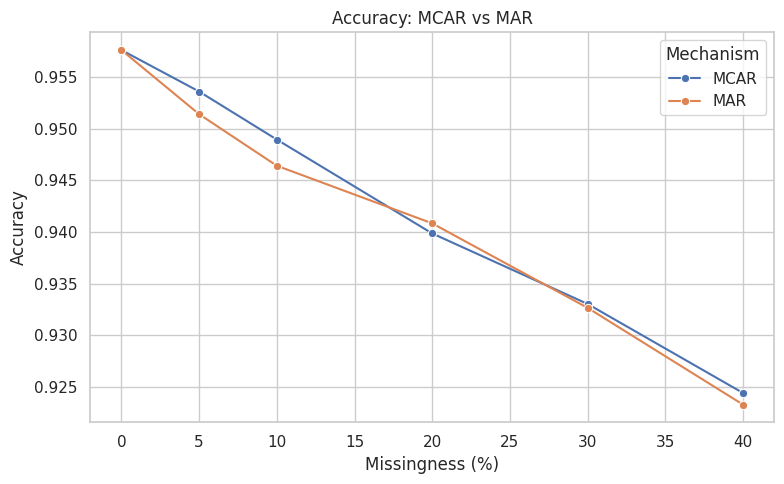

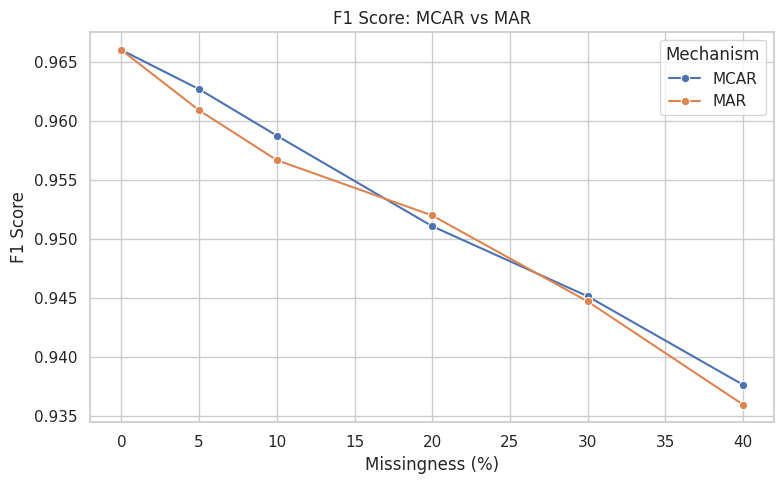

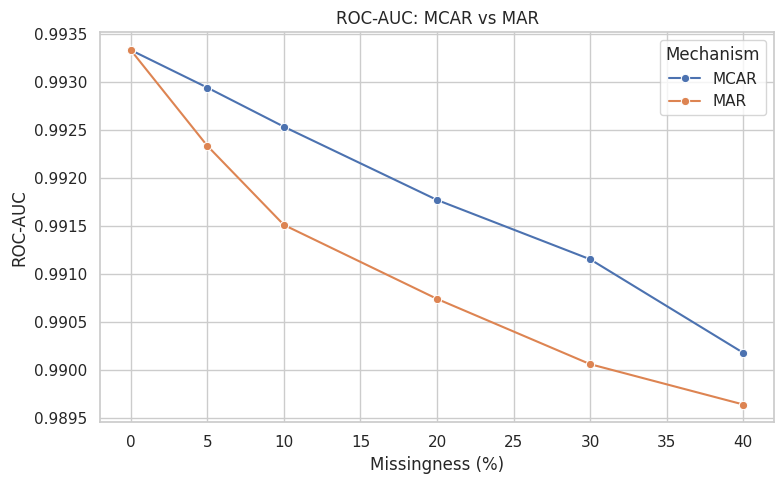

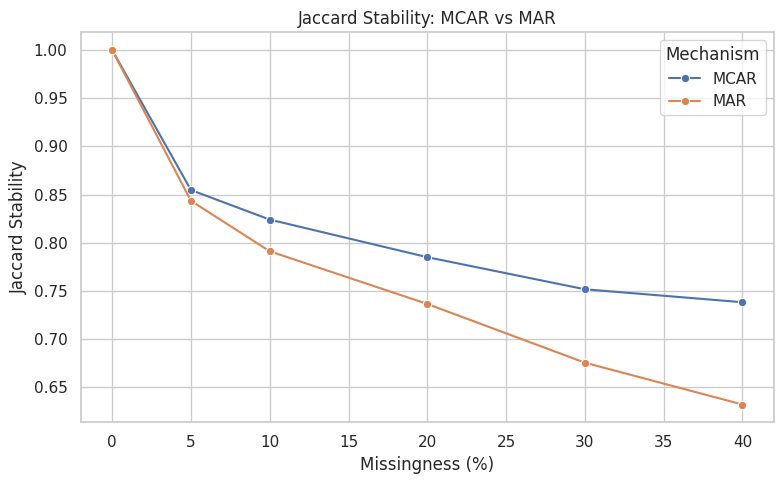

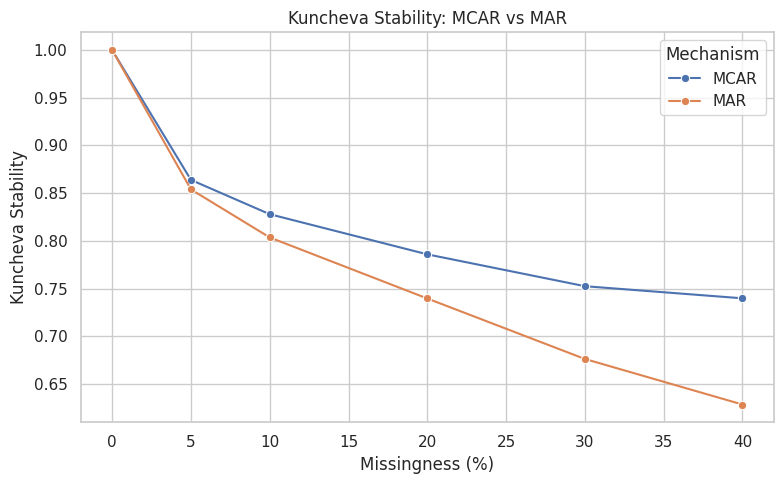

Comparison plotting completed.
Saved plots: ['F1_MCAR_vs_MAR.png', 'Average_Kuncheva_MCAR_vs_MAR.png', 'Accuracy_MCAR_vs_MAR.png', 'Average_Jaccard_MCAR_vs_MAR.png', 'ROC_AUC_MCAR_vs_MAR.png']


In [257]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("plots_comparison", exist_ok=True)

performance_comparison.columns = [
    str(c).strip() for c in performance_comparison.columns
]

aliases = {
    "Accuracy": ["Average_Accuracy", "Accuracy", "Mean_Accuracy"],
    "F1": ["Average_F1", "F1", "F1_Score", "Mean_F1"],
    "ROC_AUC": ["Average_ROC_AUC", "ROC_AUC", "ROC-AUC", "Mean_ROC_AUC"]
}

def find_column(options, columns):
    for option in options:
        if option in columns:
            return option
    return None

sns.set_theme(style="whitegrid")

metrics = [
    ("Accuracy", "Accuracy"),
    ("F1", "F1 Score"),
    ("ROC_AUC", "ROC-AUC")
]

for key, title in metrics:
    column = find_column(aliases[key], performance_comparison.columns)

    if column is None:
        print(f"Could not find {title}. Available columns:",
              performance_comparison.columns.tolist())
        continue

    plt.figure(figsize=(8, 5))

    sns.lineplot(
        data=performance_comparison,
        x="Missingness",
        y=column,
        hue="Mechanism",
        marker="o",
        errorbar=None
    )

    plt.title(f"{title}: MCAR vs MAR")
    plt.xlabel("Missingness (%)")
    plt.ylabel(title)
    plt.tight_layout()

    filename = f"plots_comparison/{key}_MCAR_vs_MAR.png"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

stability_metrics = [
    ("Average_Jaccard", "Jaccard Stability"),
    ("Average_Kuncheva", "Kuncheva Stability")
]

for metric, title in stability_metrics:
    if metric not in stability_comparison.columns:
        print(f"Missing stability column: {metric}")
        continue

    plt.figure(figsize=(8, 5))

    sns.lineplot(
        data=stability_comparison,
        x="Missingness",
        y=metric,
        hue="Mechanism",
        marker="o",
        errorbar=None
    )

    plt.title(f"{title}: MCAR vs MAR")
    plt.xlabel("Missingness (%)")
    plt.ylabel(title)
    plt.tight_layout()

    filename = f"plots_comparison/{metric}_MCAR_vs_MAR.png"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

print("Comparison plotting completed.")
print("Saved plots:", os.listdir("plots_comparison"))

In [258]:
import os
import shutil
import zipfile
import pandas as pd

BASE = "feature_selection_final"
ZIP_NAME = "feature_selection_final.zip"

folders = {
    "notebook": f"{BASE}/01_Colab_Notebook",
    "raw": f"{BASE}/02_Raw_Results",
    "final": f"{BASE}/03_Final_Results",
    "figures": f"{BASE}/04_Figures",
    "notes": f"{BASE}/05_Project_Notes"
}

# Create clean project folders
if os.path.exists(BASE):
    shutil.rmtree(BASE)

if os.path.exists(ZIP_NAME):
    os.remove(ZIP_NAME)

for folder in folders.values():
    os.makedirs(folder, exist_ok=True)

# Copy notebook, if available
notebook_candidates = [
    "/content/feature_selection.ipynb",
    "feature_selection.ipynb"
]

notebook_found = False

for path in notebook_candidates:
    if os.path.isfile(path):
        shutil.copy2(path, folders["notebook"])
        notebook_found = True
        break

# Copy raw MCAR and MAR results
for source in ["results", "results_mar", "results_comparison"]:
    if os.path.isdir(source):
        for root, dirs, files in os.walk(source):
            for file in files:
                if file.endswith(".csv"):
                    src = os.path.join(root, file)
                    relative = os.path.relpath(src, source)
                    destination_dir = os.path.join(
                        folders["raw"], source, os.path.dirname(relative)
                    )
                    os.makedirs(destination_dir, exist_ok=True)
                    shutil.copy2(
                        src,
                        os.path.join(destination_dir, file)
                    )

# Copy comparison plots
for source in ["plots", "plots_comparison"]:
    if os.path.isdir(source):
        for root, dirs, files in os.walk(source):
            for file in files:
                if file.lower().endswith((".png", ".jpg", ".jpeg", ".pdf")):
                    src = os.path.join(root, file)
                    relative = os.path.relpath(src, source)
                    destination_dir = os.path.join(
                        folders["figures"], source, os.path.dirname(relative)
                    )
                    os.makedirs(destination_dir, exist_ok=True)
                    shutil.copy2(
                        src,
                        os.path.join(destination_dir, file)
                    )

# Copy existing final tables if available
final_table_names = [
    "overall_results_table.csv",
    "method_stability_table.csv",
    "method_performance_table.csv",
    "imputation_stability_table.csv",
    "imputation_performance_table.csv",
    "combined_results.csv"
]

for filename in final_table_names:
    candidates = [
        os.path.join("03_Final_Results", filename),
        os.path.join("results", filename),
        filename
    ]

    for path in candidates:
        if os.path.isfile(path):
            shutil.copy2(path, folders["final"])
            break

# Save MCAR vs MAR comparison tables
for filename in [
    "MCAR_vs_MAR_stability.csv",
    "MCAR_vs_MAR_performance.csv"
]:
    path = os.path.join("results_comparison", filename)
    if os.path.isfile(path):
        shutil.copy2(path, folders["final"])

# Create README
readme = """
FEATURE SELECTION STABILITY UNDER MISSING DATA
==============================================

Project overview
----------------
This project investigates feature-selection stability and predictive
performance under missing data using the Breast Cancer Wisconsin
(Diagnostic) dataset.

Missingness mechanisms
----------------------
1. MCAR: Missing Completely at Random.
2. MAR: Missingness influenced by the observed mean-radius feature.
   This represents the particular MAR mechanism implemented in this study.

Experimental setup
------------------
- Missingness levels: 0%, 5%, 10%, 20%, 30%, 40%.
- Imputation: Mean, Median, KNN.
- Feature selection: Pearson, ANOVA, Mutual Information,
  Random Forest, LASSO, RFE.
- Selected features: Top 10.
- Repetitions: 30 per condition.
- Stability metrics: Jaccard and Kuncheva indices.
- Performance metrics: Accuracy, Precision, Recall, F1 and ROC-AUC.
- Evaluation: Fixed stratified train/test split; test data remains clean.

Main observations
-----------------
Feature-selection stability decreases as missingness increases.
The observed MAR mechanism generally produces lower stability than MCAR
at nonzero missingness levels. Predictive performance decreases more
gradually, so good predictive performance does not necessarily imply
stable feature selection.

Limitations
-----------
- Only one dataset was evaluated.
- Only one fixed train/test split was used.
- The MAR experiment represents one specific MAR mechanism.
- Results should not be generalized to every dataset or missingness
  mechanism.

Folder guide
------------
01_Colab_Notebook: Experimental notebook.
02_Raw_Results: Raw MCAR, MAR and comparison CSV files.
03_Final_Results: Final summary and comparison tables.
04_Figures: Existing plots and MCAR-versus-MAR comparison plots.
05_Project_Notes: Project documentation.
"""

with open(os.path.join(folders["notes"], "README.txt"), "w") as f:
    f.write(readme.strip() + "\n")

# Create ZIP
with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(BASE):
        for file in files:
            path = os.path.join(root, file)
            zipf.write(path, path)

# Verify ZIP contents
with zipfile.ZipFile(ZIP_NAME, "r") as zipf:
    contents = zipf.namelist()

print("PROJECT FOLDER CREATED")
print("Notebook copied:", notebook_found)
print("\nFiles included:", len(contents))

for item in contents:
    print(item)

print("\nZIP created:", ZIP_NAME)
print("ZIP size:", round(os.path.getsize(ZIP_NAME) / 1024, 2), "KB")

# Check important deliverables
print("\nDELIVERABLE CHECK")
print("Notebook:", any("feature_selection.ipynb" in x for x in contents))
print("README:", any("README.txt" in x for x in contents))
print("MCAR raw results:", any("/results/" in x for x in contents))
print("MAR raw results:", any("/results_mar/" in x for x in contents))
print("Comparison plots:", any("plots_comparison" in x for x in contents))
print("Final tables folder:", any("/03_Final_Results/" in x for x in contents))

PROJECT FOLDER CREATED
Notebook copied: False

Files included: 48
feature_selection_final/04_Figures/plots_comparison/F1_MCAR_vs_MAR.png
feature_selection_final/04_Figures/plots_comparison/Average_Kuncheva_MCAR_vs_MAR.png
feature_selection_final/04_Figures/plots_comparison/Accuracy_MCAR_vs_MAR.png
feature_selection_final/04_Figures/plots_comparison/Average_Jaccard_MCAR_vs_MAR.png
feature_selection_final/04_Figures/plots_comparison/ROC_AUC_MCAR_vs_MAR.png
feature_selection_final/04_Figures/plots/Figure_4_Stability_vs_Accuracy.png
feature_selection_final/04_Figures/plots/Figure_1_Jaccard_KNN.png
feature_selection_final/04_Figures/plots/Figure_2_Kuncheva_Mean.png
feature_selection_final/04_Figures/plots/Figure_5_Imputation_vs_Stability.png
feature_selection_final/04_Figures/plots/Figure_7_Feature_Recurrence_FinalDraft.png
feature_selection_final/04_Figures/plots/Figure_3_Accuracy_Median.png
feature_selection_final/04_Figures/plots/Figure_7_Feature_Recurrence.png
feature_selection_final/04

In [259]:
import os
import shutil
import zipfile
import pandas as pd
from pathlib import Path
from datetime import datetime

from google.colab import files

# ==========================================
# 1. CREATE THE MAIN PROJECT FOLDER
# ==========================================

BASE = Path("/content/feature_selection_final")
ZIP_PATH = Path("/content/feature_selection_final.zip")

if BASE.exists():
    shutil.rmtree(BASE)

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

notebook_folder = BASE / "01_Colab_Notebook"
raw_folder = BASE / "02_Raw_Results"
final_folder = BASE / "03_Final_Results"
figures_folder = BASE / "04_Figures"
notes_folder = BASE / "05_Project_Notes"

for folder in [
    notebook_folder,
    raw_folder,
    final_folder,
    figures_folder,
    notes_folder
]:
    folder.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. COPY ALL RAW EXPERIMENT RESULTS
# ==========================================

raw_sources = [
    "results",
    "results_mar",
    "results_comparison"
]

for source_name in raw_sources:
    source = Path("/content") / source_name

    if source.is_dir():
        destination = raw_folder / source_name
        shutil.copytree(source, destination)
        print("Copied raw results:", source_name)
    else:
        print("WARNING: Directory not found:", source_name)

# ==========================================
# 3. COPY ALL EXISTING FINAL RESULT TABLES
# ==========================================

final_sources = [
    Path("/content/03_Final_Results"),
    Path("/content/03_Final_Results"),
    Path("/content/results_comparison")
]

for source in final_sources:
    if not source.is_dir():
        continue

    for file_path in source.rglob("*"):
        if file_path.is_file() and file_path.suffix.lower() == ".csv":
            if source.name == "results_comparison":
                destination = final_folder / file_path.name
            else:
                destination = final_folder / file_path.name

            shutil.copy2(file_path, destination)

# ==========================================
# 4. COPY ALL GRAPHS AND FIGURES
# ==========================================

figure_sources = [
    "plots",
    "plots_comparison"
]

for source_name in figure_sources:
    source = Path("/content") / source_name

    if source.is_dir():
        destination = figures_folder / source_name
        shutil.copytree(source, destination)
        print("Copied figures:", source_name)
    else:
        print("WARNING: Plot directory not found:", source_name)

# ==========================================
# 5. COPY NOTEBOOK IF IT EXISTS IN CONTENT
# ==========================================

notebook_candidates = [
    Path("/content/feature_selection.ipynb"),
    Path("/content/feature_selection_final.ipynb")
]

notebook_found = False

for candidate in notebook_candidates:
    if candidate.is_file():
        shutil.copy2(candidate, notebook_folder / candidate.name)
        notebook_found = True
        print("Copied notebook:", candidate.name)
        break

if not notebook_found:
    print("\nIMPORTANT: Notebook file not found in /content.")
    print("Save/download your notebook from Colab and add it to")
    print("01_Colab_Notebook before making your final submission.")

# ==========================================
# 6. CREATE README
# ==========================================

readme = """
FEATURE SELECTION STABILITY UNDER MISSING DATA
================================================

PROJECT OVERVIEW
----------------
This project investigates feature-selection stability under missing
data using the Breast Cancer Wisconsin Diagnostic dataset.

MISSINGNESS MECHANISMS
----------------------
MCAR: Missing Completely at Random.
MAR: Missingness influenced by the observed mean-radius feature.

EXPERIMENTAL SETUP
------------------
Missingness levels: 0%, 5%, 10%, 20%, 30%, 40%.
Imputation: Mean, Median, KNN.
Feature selection: Pearson, ANOVA, Mutual Information,
Random Forest, LASSO, RFE.
Selected features: Top 10.
Repetitions: 30 per condition.

STABILITY METRICS
-----------------
Jaccard Index.
Kuncheva Index.

PREDICTION METRICS
------------------
Accuracy, Precision, Recall, F1 Score, ROC-AUC.

MAIN OBSERVATION
----------------
Feature-selection stability decreases as missingness increases.
In the tested experiment, the specified MAR mechanism generally
produced lower stability than MCAR at nonzero missingness levels.
Predictive performance decreased more gradually.

LIMITATIONS
-----------
Only one dataset and one fixed train/test split were evaluated.
The MAR experiment represents one particular MAR mechanism.
The findings should not be generalized to every dataset or
missingness mechanism.

FOLDER GUIDE
------------
01_Colab_Notebook: Experimental notebook, if available.
02_Raw_Results: Original MCAR, MAR and comparison results.
03_Final_Results: Final summary and comparison tables.
04_Figures: Plots and comparison figures.
05_Project_Notes: Documentation.
"""

(notes_folder / "README.txt").write_text(
    readme.strip() + "\n",
    encoding="utf-8"
)

# ==========================================
# 7. CREATE A MANIFEST OF ALL INCLUDED FILES
# ==========================================

manifest_rows = []

for file_path in sorted(BASE.rglob("*")):
    if file_path.is_file():
        manifest_rows.append({
            "Relative_Path": str(file_path.relative_to(BASE)),
            "File_Size_KB": round(file_path.stat().st_size / 1024, 2)
        })

manifest = pd.DataFrame(manifest_rows)

manifest.to_csv(
    notes_folder / "file_manifest.csv",
    index=False
)

# ==========================================
# 8. VERIFY IMPORTANT RESULT FILES
# ==========================================

print("\n========== FILE VERIFICATION ==========")

all_files = [
    p for p in BASE.rglob("*")
    if p.is_file()
]

for folder in [
    notebook_folder,
    raw_folder,
    final_folder,
    figures_folder,
    notes_folder
]:
    print(f"{folder.name}: {sum(1 for p in folder.rglob('*') if p.is_file())} files")

print("\nRaw MCAR files:",
      sum(1 for p in (raw_folder / "results").rglob("*") if p.is_file())
      if (raw_folder / "results").exists() else 0)

print("Raw MAR files:",
      sum(1 for p in (raw_folder / "results_mar").rglob("*") if p.is_file())
      if (raw_folder / "results_mar").exists() else 0)

print("Comparison files:",
      sum(1 for p in (raw_folder / "results_comparison").rglob("*") if p.is_file())
      if (raw_folder / "results_comparison").exists() else 0)

print("Figure files:",
      sum(1 for p in figures_folder.rglob("*") if p.is_file()))

print("\nFiles currently included:", len(all_files))

# ==========================================
# 9. CREATE ONE ZIP FILE
# ==========================================

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file_path in BASE.rglob("*"):
        if file_path.is_file():
            archive.write(
                file_path,
                arcname=str(file_path.relative_to(BASE.parent))
            )

# Verify ZIP integrity
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_file = archive.testzip()
    zip_contents = archive.namelist()

print("\n========== ZIP VERIFICATION ==========")
print("ZIP integrity:", "PASS" if bad_file is None else f"FAILED: {bad_file}")
print("Files inside ZIP:", len(zip_contents))
print("ZIP size:", round(ZIP_PATH.stat().st_size / (1024 * 1024), 2), "MB")

print("\nFinal ZIP path:", ZIP_PATH)
print("\nIf the checks look correct, the next step is to download the ZIP.")

Copied raw results: results
Copied raw results: results_mar
Copied raw results: results_comparison
Copied figures: plots
Copied figures: plots_comparison

IMPORTANT: Notebook file not found in /content.
Save/download your notebook from Colab and add it to
01_Colab_Notebook before making your final submission.

========== FILE VERIFICATION ==========
01_Colab_Notebook: 0 files
02_Raw_Results: 18 files
03_Final_Results: 12 files
04_Figures: 21 files
05_Project_Notes: 2 files

Raw MCAR files: 8
Raw MAR files: 4
Comparison files: 6
Figure files: 21

Files currently included: 53

========== ZIP VERIFICATION ==========
ZIP integrity: PASS
Files inside ZIP: 53
ZIP size: 4.84 MB

Final ZIP path: /content/feature_selection_final.zip

If the checks look correct, the next step is to download the ZIP.


In [261]:
from google.colab import files
files.download("/content/feature_selection_final.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>